# Data analysis and research design

In [1]:
from pathlib import Path
import re, json, hashlib, zipfile, io
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Image, Markdown
from bs4 import BeautifulSoup
from scipy import stats

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / "dataset").is_dir() and (path / "notebooks").is_dir())
OUTPUT_ROOT = REPO_ROOT / "artifacts"  # generated tables, models, predictions and figures
(OUTPUT_ROOT / "Configs").mkdir(parents=True, exist_ok=True)
SHARED_DATASET_ROOT = REPO_ROOT / "dataset"
for folder in ["Processed", "Interim", "Features", "Splits"]:
    (SHARED_DATASET_ROOT / folder).mkdir(parents=True, exist_ok=True)
RUN_ID = "racf_20261011"
TABLES = OUTPUT_ROOT / "Tables" / RUN_ID
PNG = OUTPUT_ROOT / "Figures/PNG/publication_20261012"
PDF = OUTPUT_ROOT / "Figures/PDF/publication_20261012"
for folder in [TABLES, PNG, PDF, SHARED_DATASET_ROOT / "Interim", SHARED_DATASET_ROOT / "Processed"]:
    folder.mkdir(parents=True, exist_ok=True)
np.random.seed(42)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)
font_manager.findfont("Times New Roman", fallback_to_default=False)
mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
    "axes.titlesize": 20, "axes.labelsize": 19, "xtick.labelsize": 18,
    "ytick.labelsize": 18, "legend.fontsize": 18, "figure.titlesize": 20,
    "figure.dpi": 350, "savefig.dpi": 350, "axes.unicode_minus": True,
    "pdf.fonttype": 42, "ps.fonttype": 42, "mathtext.fontset": "custom", "mathtext.rm": "Times New Roman", "mathtext.it": "Times New Roman:italic", "mathtext.bf": "Times New Roman:bold"})
plt.ioff();


In [2]:
def scientific_table(frame: pd.DataFrame, name: str, caption: str) -> None:
    """Display every selected row and column and retain numerical source values."""
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    display(Markdown(f"**{caption}**"))
    display(frame.style.format(precision=4, na_rep="Unavailable").hide(axis="index"))


def publication_figure(fig, name: str, numerical_source: pd.DataFrame, caption: str) -> None:
    """Save the same 350-DPI canvas once and verify the actual visible fonts."""
    fig.canvas.draw()
    for text in fig.findobj(mpl.text.Text):
        if text.get_visible() and text.get_text().strip():
            assert 18 <= text.get_fontsize() <= 20, text.get_text()
            font_path = font_manager.findfont(text.get_fontproperties(), fallback_to_default=False)
            assert "Times New Roman" in font_manager.FontProperties(fname=font_path).get_name()
    fig.savefig(PNG / f"{name}.png", dpi=350, bbox_inches="tight", pad_inches=0.12)
    fig.savefig(PDF / f"{name}.pdf", dpi=350, bbox_inches="tight", pad_inches=0.12)
    numerical_source.to_csv(TABLES / f"{name}_source.csv", index=False)
    plt.close(fig)
    display(Image(filename=str(PNG / f"{name}.png"), width=1000))
    display(Markdown(caption))


def normalize_name(value: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def normalize_docket(value) -> str:
    digits = re.sub(r"\D", "", str(value)).lstrip("0")
    assert digits[:2] in {"50", "52"}, value
    return f"0{digits[:2]}{int(digits[2:]):05d}"


## Observation coverage and provenance

In [3]:
power_parts = []
for year in range(2019, 2026):
    part = pd.read_csv(SHARED_DATASET_ROOT / f"Raw/NRC_Power_Status/power_status_{year}.txt", sep="|")
    assert list(part.columns) == ["ReportDt", "Unit", "Power"]
    part = part.rename(columns={"ReportDt": "date", "Unit": "source_unit", "Power": "power_pct"})
    part["date"] = pd.to_datetime(part["date"], format="%m/%d/%Y %I:%M:%S %p").dt.normalize()
    part["source_year"] = year
    part["source_record_id"] = [f"NRC-power-{year}-{i+2}" for i in range(len(part))]
    assert part["date"].dt.year.eq(year).all()
    power_parts.append(part)
raw_power = pd.concat(power_parts, ignore_index=True)
source_coverage = raw_power.groupby("source_year").agg(
    records=("source_record_id", "size"), source_unit_names=("source_unit", "nunique"),
    calendar_days=("date", "nunique")).reset_index()
source_coverage["role"] = ["Train"]*4 + ["Development", "Calibration", "Locked test: integrity only"]
scientific_table(source_coverage, "nb01_source_coverage", "NRC Power Status coverage; unit names before identifier reconciliation")


**NRC Power Status coverage; unit names before identifier reconciliation**

source_year,records,source_unit_names,calendar_days,role
2019,35720,100,365,Train
2020,35502,97,366,Train
2021,34649,97,365,Train
2022,33828,94,365,Train
2023,34078,94,365,Development
2024,34404,94,366,Calibration
2025,34424,95,365,Locked test: integrity only


## Reactor identity and join quality

In [4]:
operating = pd.read_excel(SHARED_DATASET_ROOT / "Raw/NRC_Reactors/reactors-operating.xlsx")
decommissioning = pd.read_excel(SHARED_DATASET_ROOT / "Raw/NRC_Reactors/reactors-decommissioning.xlsx")
scram_registry = pd.read_excel(SHARED_DATASET_ROOT / "Raw/NRC_Scrams/scram-event-notifications.xlsx", sheet_name="Public Site Data")
scram_registry.columns = scram_registry.columns.str.strip()
registry_rows = []
for row in operating.to_dict("records"):
    registry_rows.append({"registry_name": row["NRC Reactor Unit Web Page"],
        "reactor_id": normalize_docket(row["Docket Number"]),
        "reactor_type": str(row["Reactor and Containment Type"]).strip().split("-")[0].strip(),
        "commercial_date": pd.to_datetime(row["Commercial Operation"], errors="coerce"),
        "registry_source": "NRC operating workbook"})
for row in decommissioning.to_dict("records"):
    registry_rows.append({"registry_name": str(row["Unit"]).strip(),
        "reactor_id": normalize_docket(row["Docket Number"]),
        "reactor_type": str(row["Reactor Type"]).strip(), "commercial_date": pd.NaT,
        "registry_source": "NRC decommissioning workbook"})
for short_name, pattern in [("Pilgrim 1", "Pilgrim"), ("Palisades", "Palisades"), ("Vogtle 4", "Vogtle.*Unit 4")]:
    matches = scram_registry.loc[scram_registry["Plant Name"].str.contains(pattern), ["Docket", "PWR/BWR"]].drop_duplicates()
    assert len(matches) == 1
    registry_rows.append({"registry_name": short_name,
        "reactor_id": normalize_docket(matches.iloc[0]["Docket"]),
        "reactor_type": {"P": "PWR", "B": "BWR"}[matches.iloc[0]["PWR/BWR"]],
        "commercial_date": pd.NaT, "registry_source": "NRC SCRAM unit identifier"})
reactor_registry = pd.DataFrame(registry_rows)
reactor_registry["name_key"] = reactor_registry["registry_name"].map(normalize_name)
reactor_registry = reactor_registry.drop_duplicates("name_key")
name_aliases = {"arkansasnuclear1": "ano1", "arkansasnuclear2": "ano2",
    "harris1": "shearonharris1", "riverbendstation1": "riverbend1", "pilgrim": "pilgrim1"}
unit_mapping = raw_power[["source_unit"]].drop_duplicates().copy()
unit_mapping["name_key"] = unit_mapping["source_unit"].map(normalize_name).replace(name_aliases)
unit_mapping = unit_mapping.merge(reactor_registry, on="name_key", how="left", validate="many_to_one")


In [5]:
mapping_summary = pd.DataFrame({"Mapping status": ["Mapped source names", "Unmapped source names", "Distinct mapped dockets"],
    "n": [unit_mapping.reactor_id.notna().sum(), unit_mapping.reactor_id.isna().sum(), unit_mapping.reactor_id.nunique()]})
scientific_table(mapping_summary, "nb01_mapping_coverage", "Completeness of reactor-to-docket matching")
if unit_mapping.reactor_id.isna().any():
    scientific_table(unit_mapping.loc[unit_mapping.reactor_id.isna(), ["source_unit"]], "nb01_unmapped_units", "Unmatched names require a separate official source")


**Completeness of reactor-to-docket matching**

Mapping status,n
Mapped source names,102
Unmapped source names,0
Distinct mapped dockets,101


## Data structure, duplicates and observed regimes

In [6]:
assert unit_mapping.reactor_id.notna().all(), "Unresolved reactor identifier"
power = raw_power.merge(unit_mapping[["source_unit", "reactor_id", "reactor_type", "registry_source"]], on="source_unit", validate="many_to_one")
key = ["reactor_id", "date"]
conflicts = power.groupby(key).power_pct.nunique(dropna=False)
assert conflicts.le(1).all(), "Conflicting same-day reactor powers"
source_links = power.groupby(key).source_record_id.agg(";".join).rename("source_record_ids")
power = power.drop_duplicates(key).merge(source_links, on=key, validate="one_to_one")
power = power.sort_values(key).reset_index(drop=True)
power["power_pct"] = pd.to_numeric(power.power_pct, errors="coerce")
power["invalid_power"] = ~power.power_pct.between(0, 110) & power.power_pct.notna()
power.loc[power.invalid_power, "power_pct"] = np.nan
power["observation_id"] = power.reactor_id + "_" + power.date.dt.strftime("%Y%m%d")
power["day_gap"] = power.groupby("reactor_id").date.diff().dt.days
power["power_change"] = power.groupby("reactor_id").power_pct.diff().where(power.day_gap.eq(1))
power["regime"] = np.select([power.power_pct.isna(), power.power_pct.eq(0), power.power_pct.lt(95)],
    ["Unavailable", "Zero", "Reduced"], default="High")
dev_power = power.loc[power.date.lt("2024-01-01")].copy()
unit_mapping.to_csv(SHARED_DATASET_ROOT / "Processed/reactor_identifier_crosswalk.csv", index=False)
quality = pd.DataFrame({"Quality dimension": ["Raw records, 2019–2023", "Unique reactor-days, 2019–2023", "Duplicate source rows merged", "Missing power", "Invalid power", "Nonconsecutive within-reactor dates", "Distinct reactors"],
    "n": [int(raw_power.source_year.le(2023).sum()), len(dev_power), int(raw_power.source_year.le(2023).sum()) - len(dev_power), int(dev_power.power_pct.isna().sum()), int(dev_power.invalid_power.sum()), int(dev_power.day_gap.gt(1).sum()), dev_power.reactor_id.nunique()]})
scientific_table(quality, "nb01_power_quality", "Numerical-series quality in the development pool")

**Numerical-series quality in the development pool**

Quality dimension,n
"Raw records, 2019–2023",173777
"Unique reactor-days, 2019–2023",173777
Duplicate source rows merged,0
Missing power,0
Invalid power,0
Nonconsecutive within-reactor dates,0
Distinct reactors,101


In [7]:
summary = dev_power.groupby(["source_year", "reactor_type"]).agg(n=("power_pct", "size"),
    reactors=("reactor_id", "nunique"), mean_pct=("power_pct", "mean"), median_pct=("power_pct", "median"),
    sd_pp=("power_pct", "std"), zero_pct=("power_pct", lambda x: 100*x.eq(0).mean())).reset_index()
scientific_table(summary, "nb01_power_statistics", "Power by year and reactor type; SD is measured in percentage points")

**Power by year and reactor type; SD is measured in percentage points**

source_year,reactor_type,n,reactors,mean_pct,median_pct,sd_pp,zero_pct
2019,BWR,11995,34,90.7586,100.0000,26.0566,6.6028
2019,PWR,23725,65,91.8069,100.0000,26.5451,7.1612
2020,BWR,11712,32,89.9577,100.0000,27.1725,7.3087
2020,PWR,23790,65,89.1883,100.0000,30.1206,9.7016
2021,BWR,11396,32,92.3256,100.0000,24.1668,5.6687
2021,PWR,23253,65,89.1174,100.0000,30.0345,9.6074
2022,BWR,11315,31,91.7906,100.0000,24.6936,5.7799
2022,PWR,22513,63,91.0342,100.0000,27.8078,8.0887
2023,BWR,11315,31,91.6864,100.0000,25.2324,6.0716
2023,PWR,22763,63,90.3559,100.0000,28.5027,8.4040


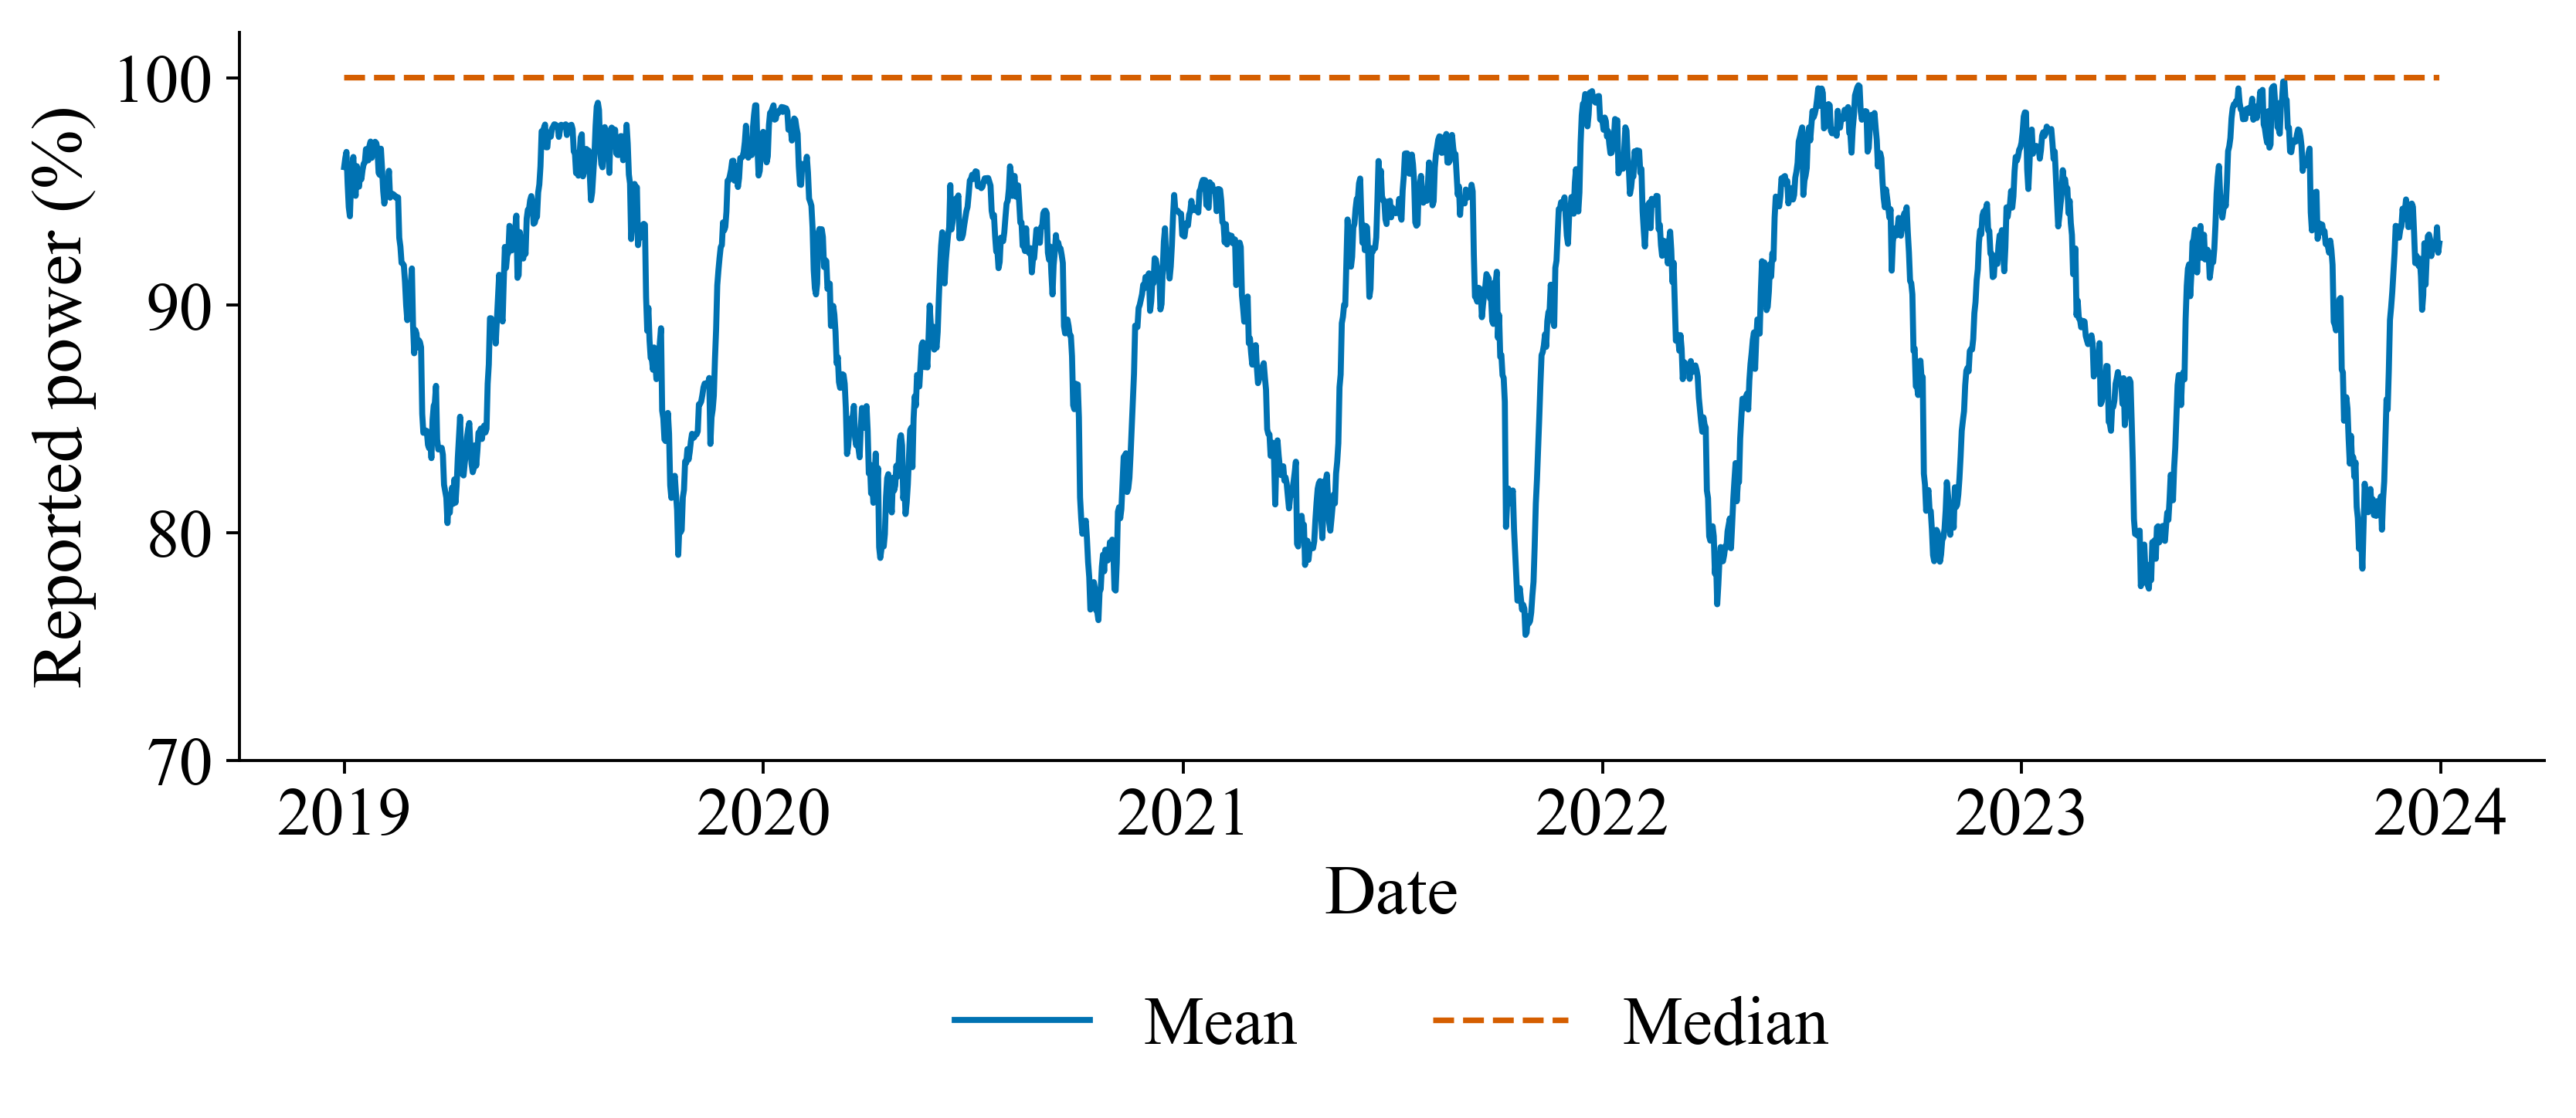

Daily mean and median reported power across available units, 2019–2023. Their difference reflects heterogeneous regimes and changing unit composition. The 70–102% scale emphasizes temporal variation.

In [8]:
daily = dev_power.groupby("date").power_pct.agg(["mean", "median", lambda x: x.quantile(.1)]).rename(columns={"<lambda_0>": "p10"}).reset_index()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.date, daily["mean"], label="Mean", color="#0072B2", lw=1.6)
ax.plot(daily.date, daily["median"], label="Median", color="#D55E00", ls="--", lw=1.5)
ax.set(xlabel="Date", ylabel="Reported power (%)", ylim=(70, 102))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.24), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_daily_power", daily,
    "Daily mean and median reported power across available units, 2019–2023. Their difference reflects heterogeneous regimes and changing unit composition. The 70–102% scale emphasizes temporal variation.")

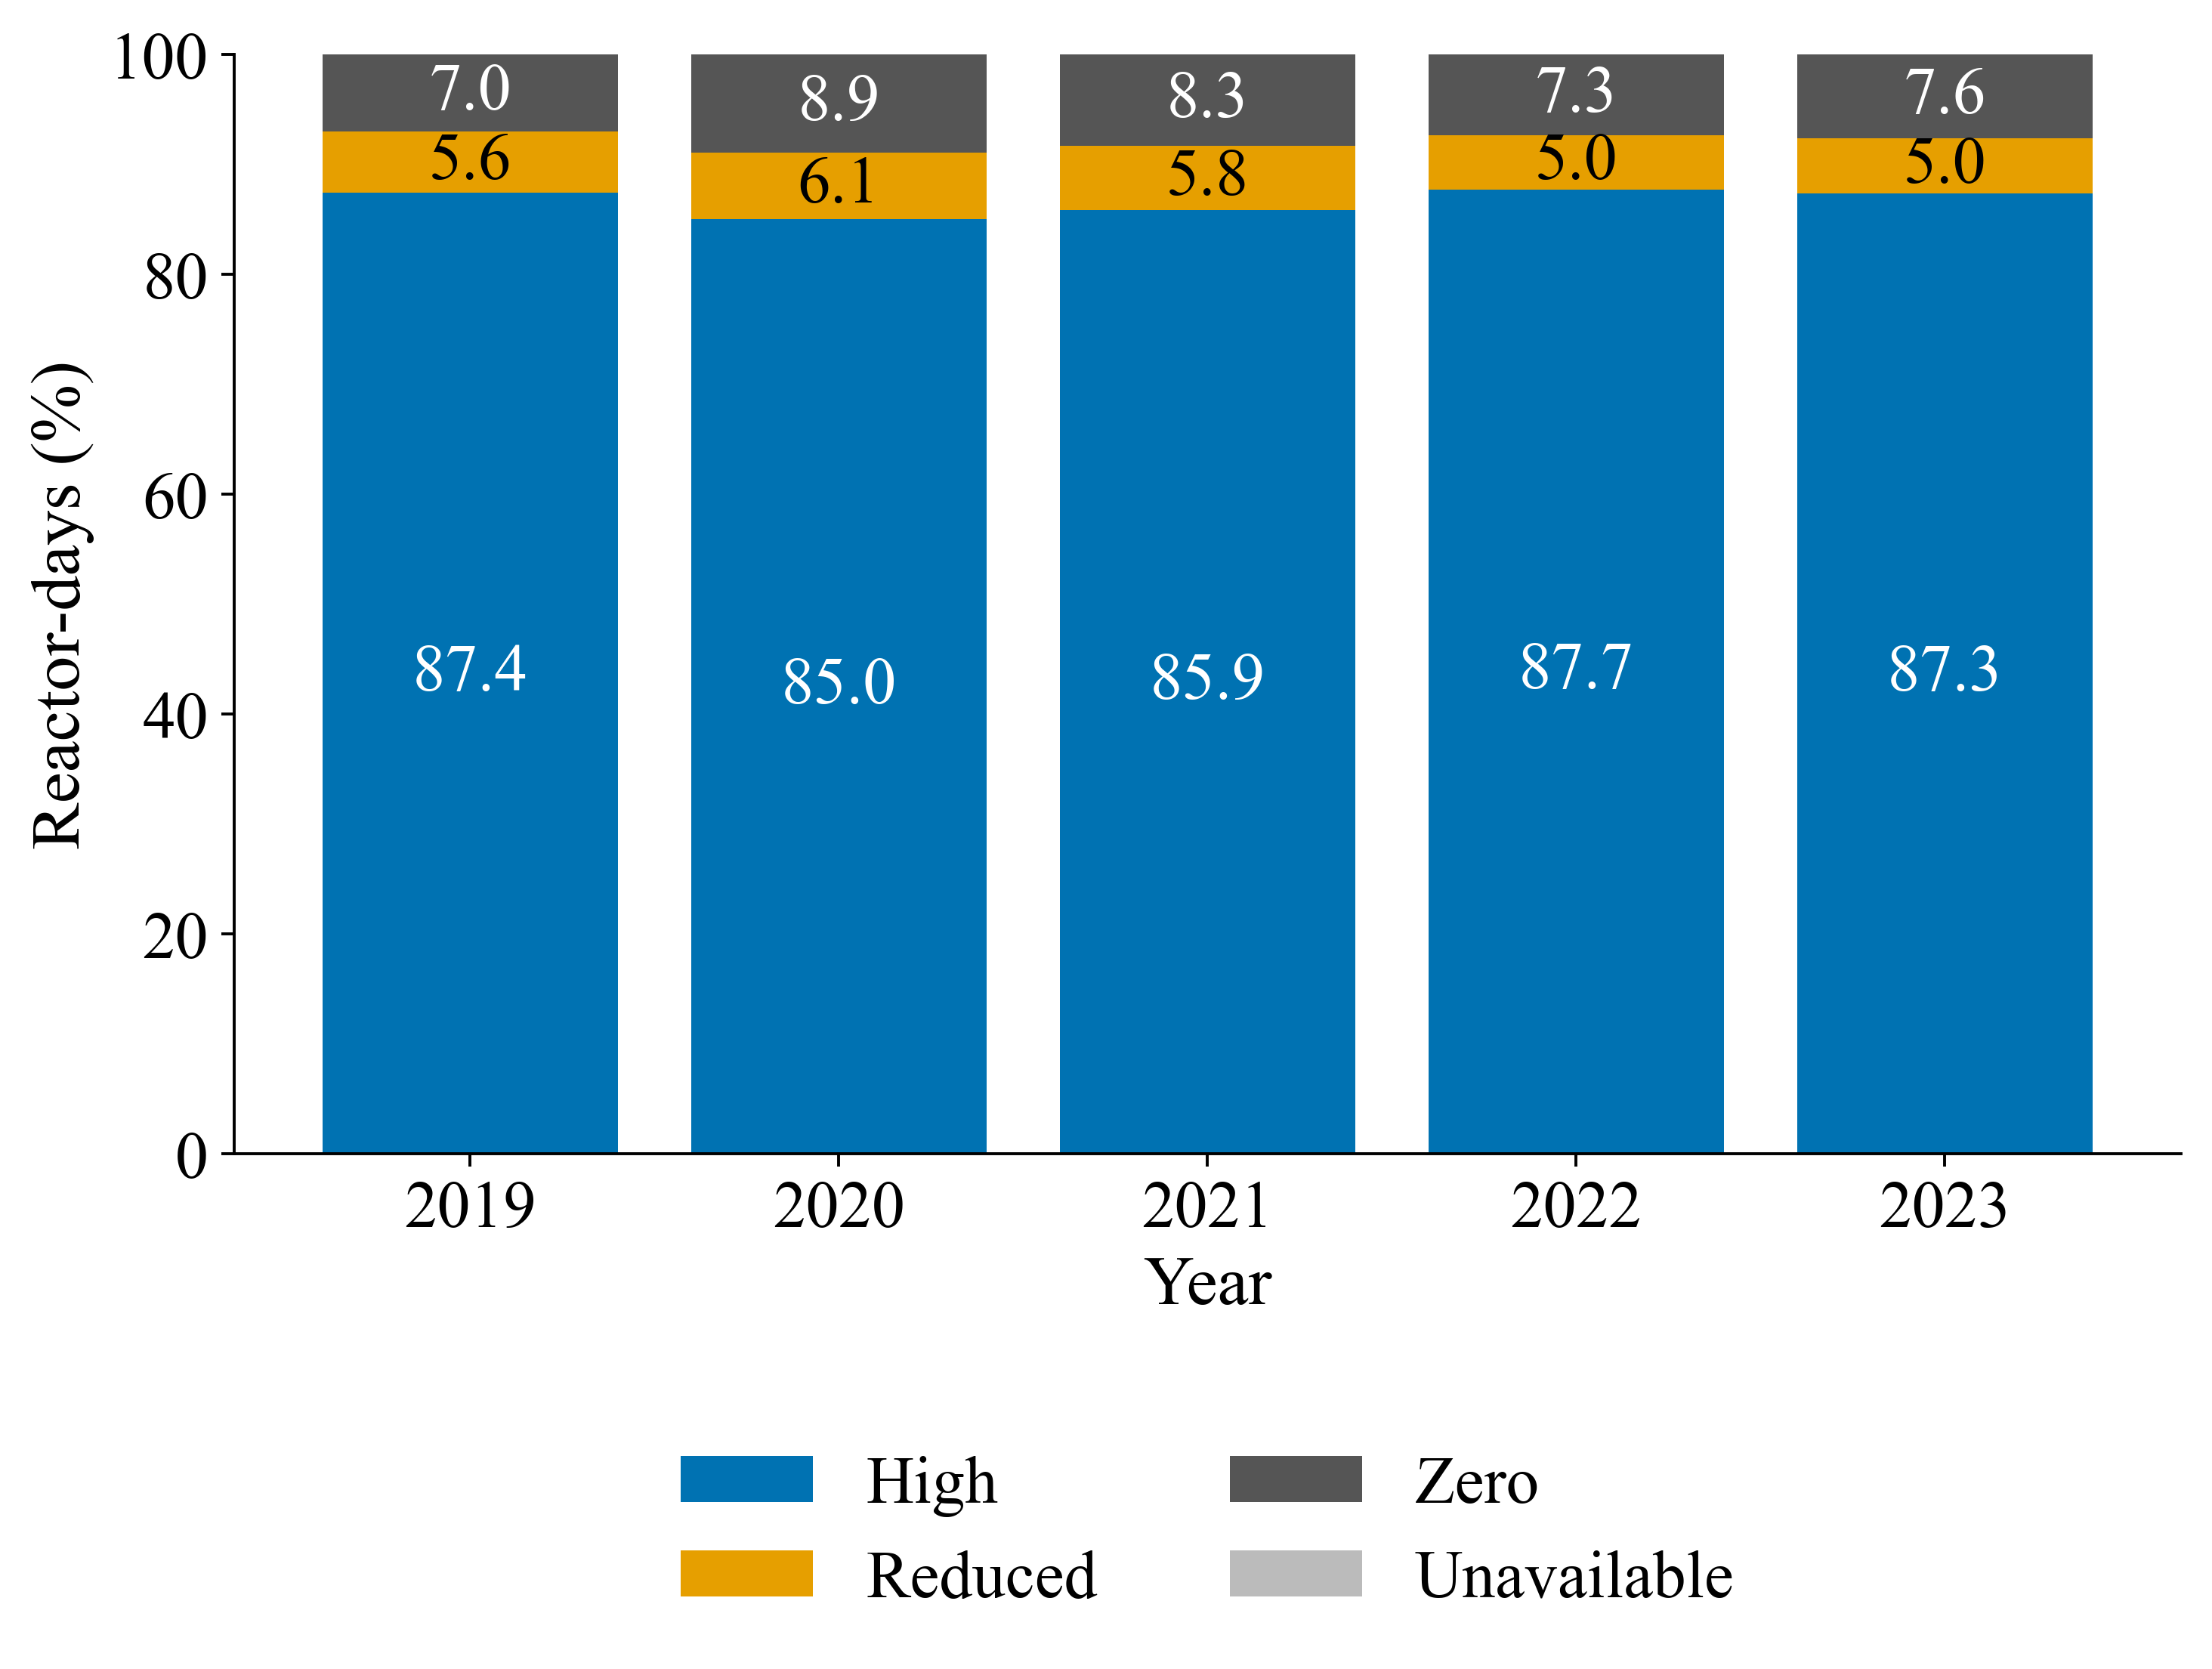

Descriptive regimes: High ≥95%, Reduced >0% and <95%, Zero =0%; Unavailable indicates missing values. Labels give percentages, rounded to one decimal. Colors do not identify technical causes of reduced power.

In [9]:
regime_counts = pd.crosstab(dev_power.source_year, dev_power.regime).reindex(columns=["High", "Reduced", "Zero", "Unavailable"], fill_value=0)
regime_share = regime_counts.div(regime_counts.sum(axis=1), axis=0)*100
fig, ax = plt.subplots(figsize=(9.5, 5.4))
bottom = np.zeros(len(regime_share))
for label, color in zip(regime_share.columns, ["#0072B2", "#E69F00", "#555555", "#BBBBBB"]):
    bars = ax.bar(regime_share.index.astype(str), regime_share[label], bottom=bottom, label=label, color=color)
    ax.bar_label(bars, labels=[f"{value:.1f}" if value > 0 else "" for value in regime_share[label]],
                 label_type="center", fontsize=18, color="black" if label in ["Reduced", "Unavailable"] else "white")
    bottom += regime_share[label].to_numpy()
ax.set(xlabel="Year", ylabel="Reactor-days (%)", ylim=(0, 100))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.22), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_operating_regimes", regime_counts.reset_index(),
    "Descriptive regimes: High ≥95%, Reduced >0% and <95%, Zero =0%; Unavailable indicates missing values. Labels give percentages, rounded to one decimal. Colors do not identify technical causes of reduced power.")

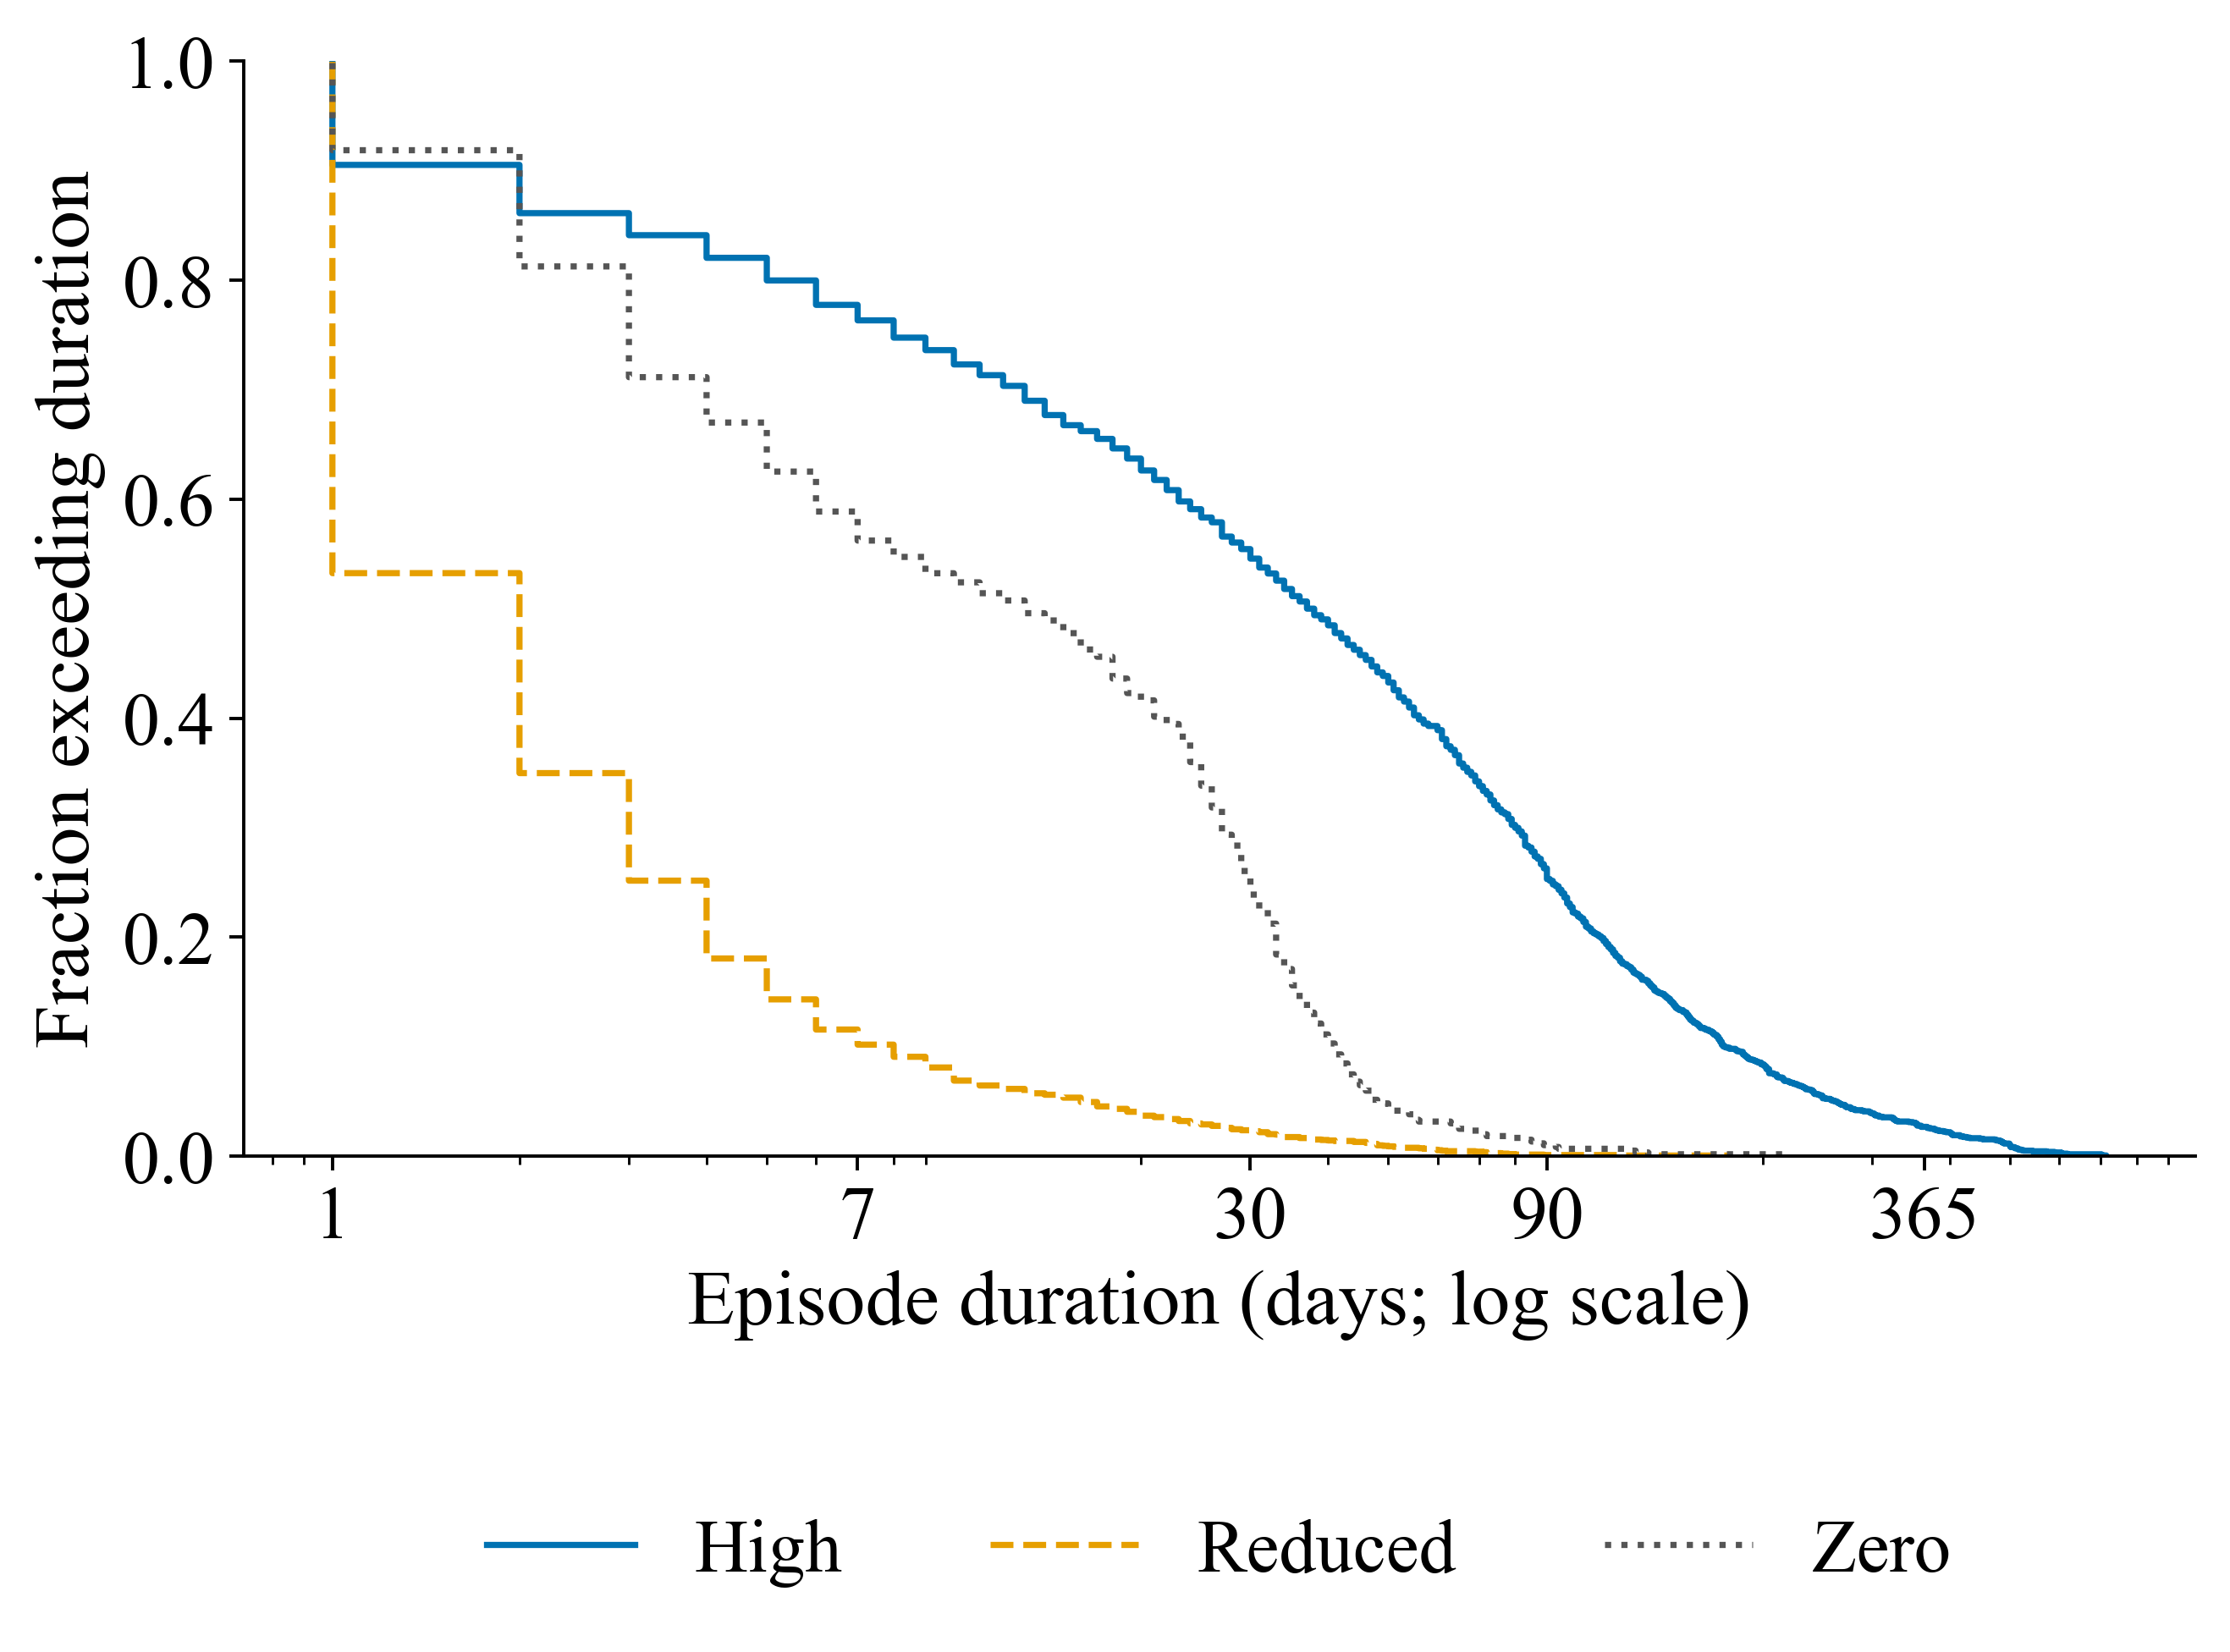

Empirical exceedance function for the duration of completed regime episodes. Episodes censored by series boundaries are excluded. This is not an estimate of equipment lifetime.

In [10]:
dev_power["episode_start"] = dev_power.regime.ne(dev_power.groupby("reactor_id").regime.shift()) | dev_power.day_gap.ne(1)
dev_power["episode_number"] = dev_power.groupby("reactor_id").episode_start.cumsum()
episodes = dev_power.groupby(["reactor_id", "episode_number", "regime"]).agg(start=("date", "min"), end=("date", "max"), duration_days=("date", "size")).reset_index()
boundaries = dev_power.groupby("reactor_id").date.agg(["min", "max"])
episodes["boundary_censored"] = episodes.start.eq(episodes.reactor_id.map(boundaries["min"])) | episodes.end.eq(episodes.reactor_id.map(boundaries["max"]))
complete_episodes = episodes.loc[~episodes.boundary_censored & episodes.regime.isin(["High", "Reduced", "Zero"])]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for label, color, style in [("High", "#0072B2", "-"), ("Reduced", "#E69F00", "--"), ("Zero", "#555555", ":")]:
    values = np.sort(complete_episodes.loc[complete_episodes.regime.eq(label), "duration_days"].to_numpy())
    ax.step(values, 1 - np.arange(1, len(values)+1)/len(values), where="post", label=label, color=color, ls=style)
ax.set(xscale="log", xlabel="Episode duration (days; log scale)", ylabel="Fraction exceeding duration", ylim=(0, 1))
ax.set_xticks([1, 7, 30, 90, 365], ["1", "7", "30", "90", "365"])
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.27), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_episode_duration", complete_episodes,
    "Empirical exceedance function for the duration of completed regime episodes. Episodes censored by series boundaries are excluded. This is not an estimate of equipment lifetime.")

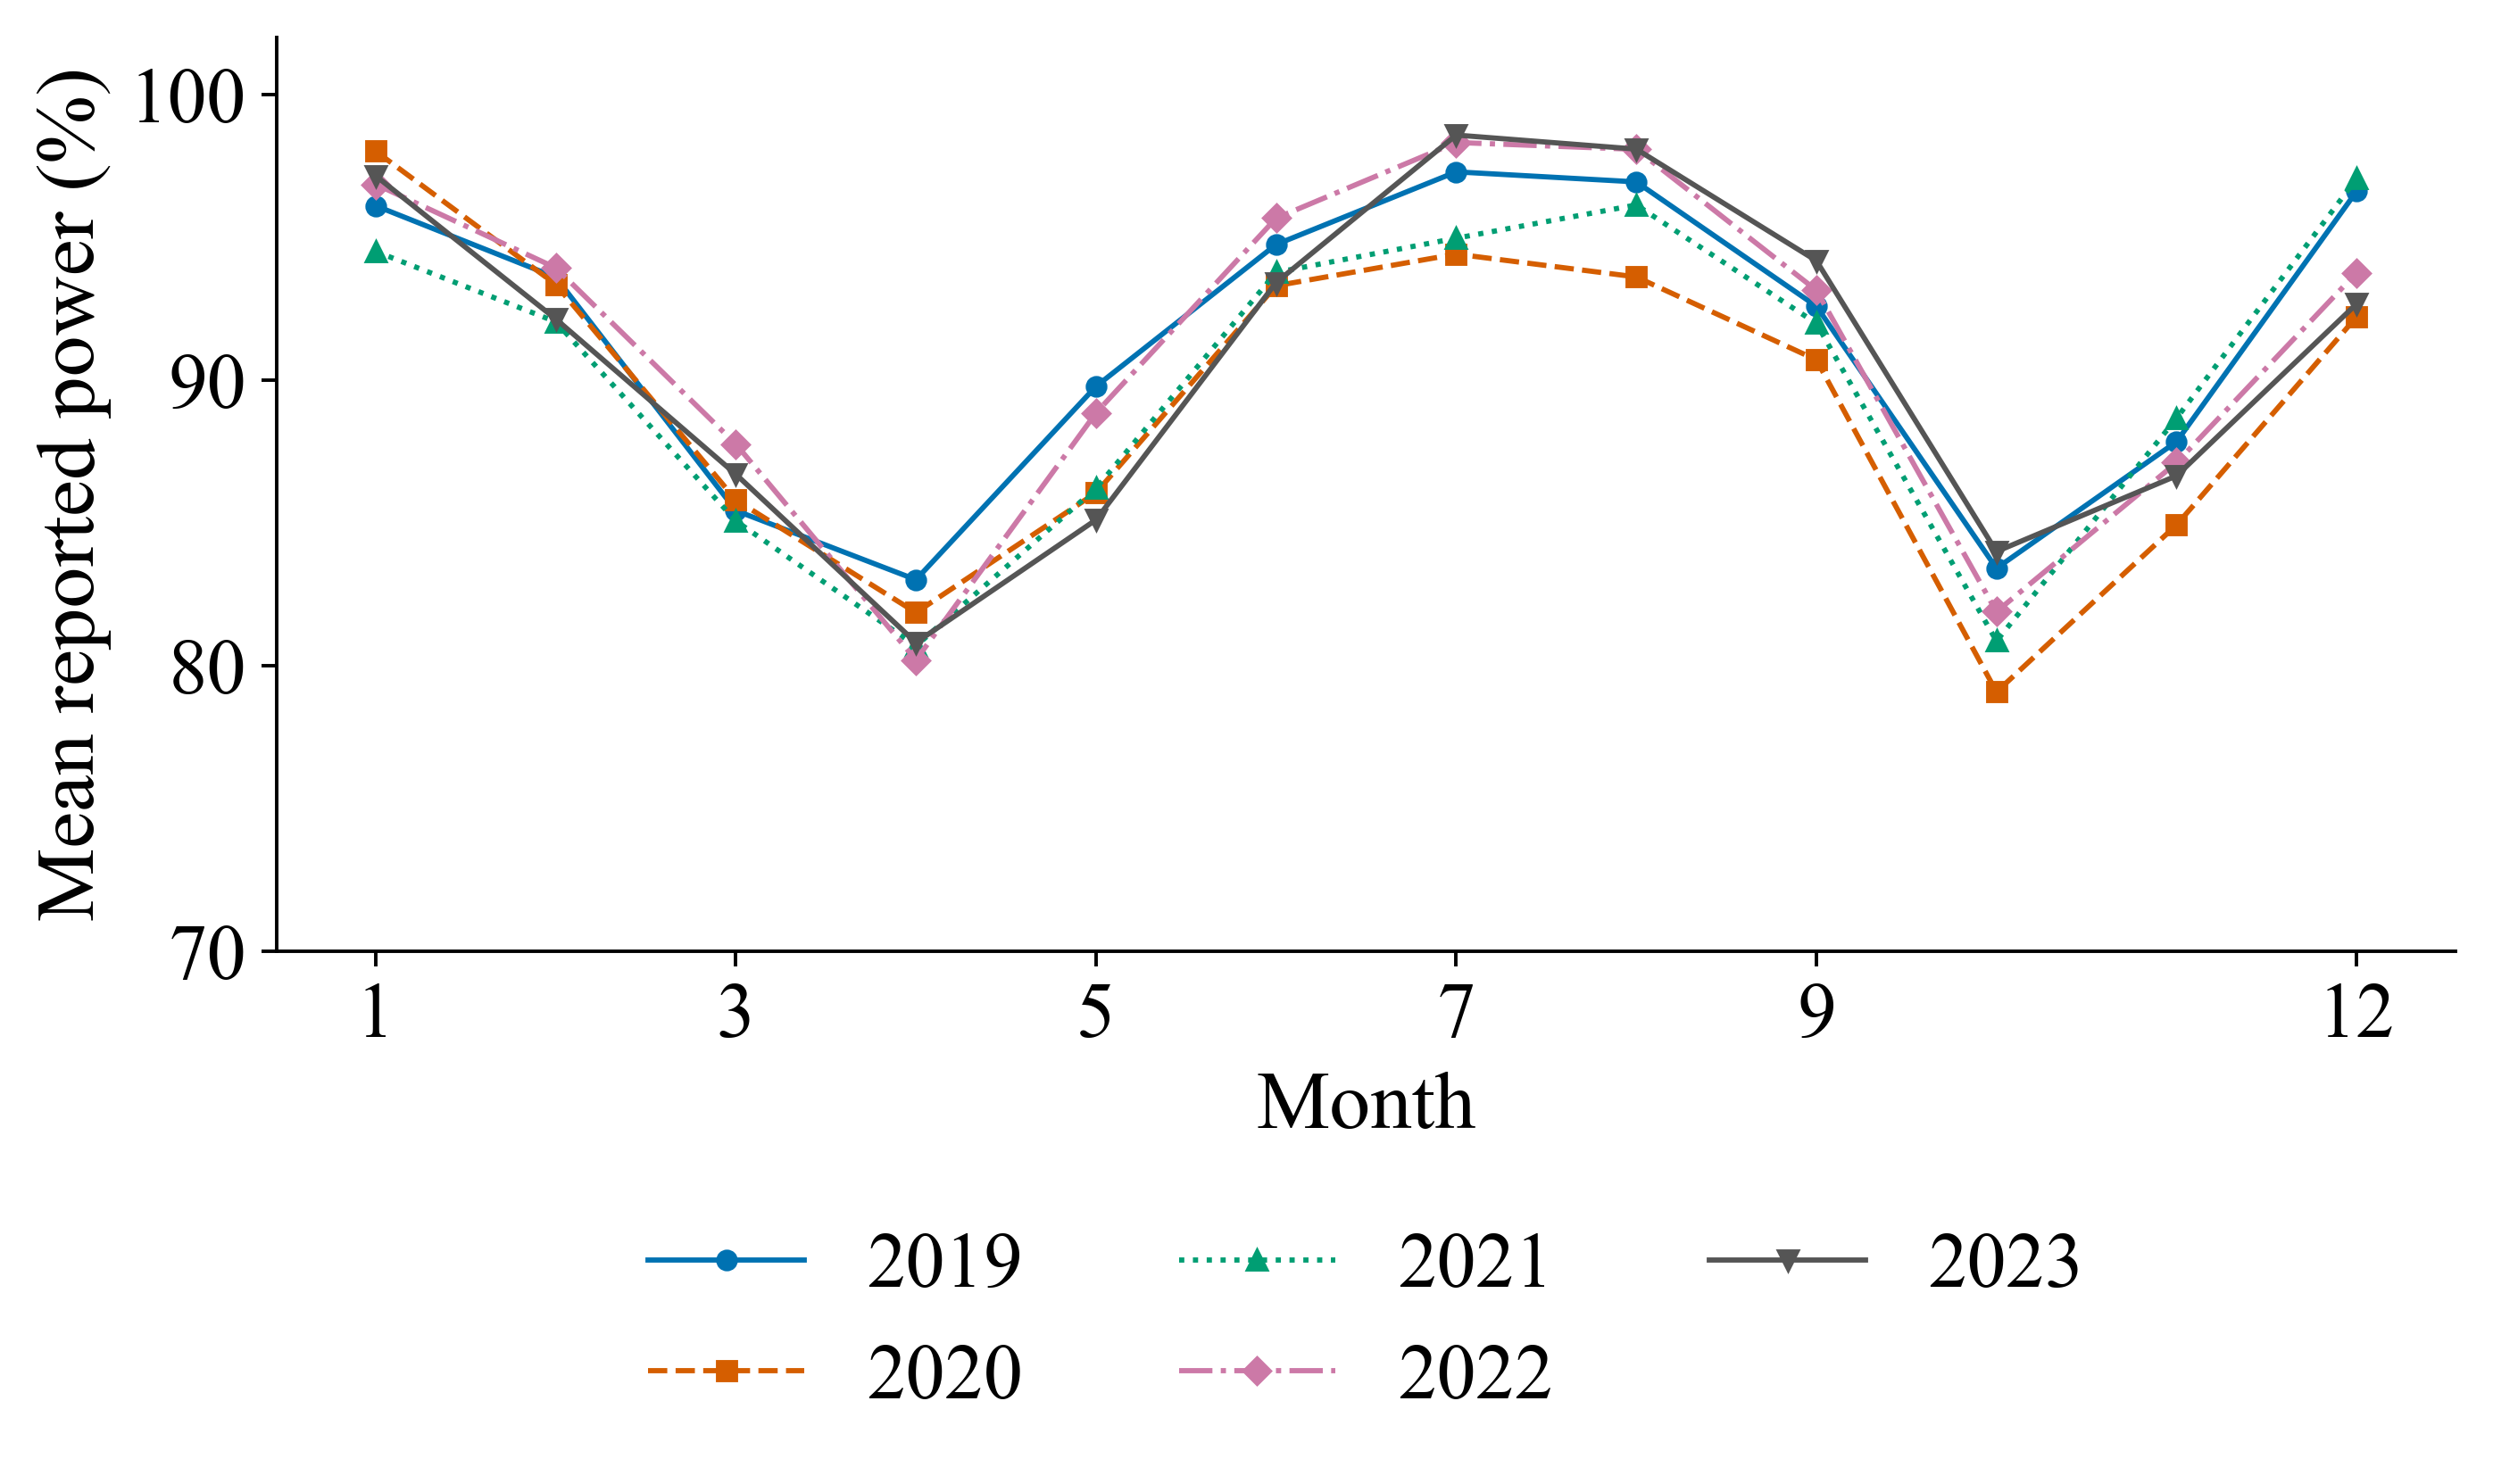

Monthly means by year in the development pool. Seasonality can reflect maintenance and cohort composition; it does not establish a temperature effect on SCRAM. Power is shown on a 70–102% scale.

In [11]:
seasonal = dev_power.assign(month=dev_power.date.dt.month).groupby(["source_year", "month"]).power_pct.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for year, color, marker, style in zip(seasonal, ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#555555"], ["o", "s", "^", "D", "v"], ["-", "--", ":", "-.", "-"]):
    ax.plot(seasonal.index, seasonal[year], color=color, marker=marker, ls=style, markersize=4, lw=1.2, label=str(year))
ax.set(xlabel="Month", ylabel="Mean reported power (%)", xticks=[1, 3, 5, 7, 9, 12], ylim=(70, 102))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.23), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_seasonality", seasonal.reset_index(),
    "Monthly means by year in the development pool. Seasonality can reflect maintenance and cohort composition; it does not establish a temperature effect on SCRAM. Power is shown on a 70–102% scale.")

## EIA and NOAA site reconciliation

In [12]:
eia_site_codes = {
    "Arkansas Nuclear":8055,"Beaver Valley":6040,"Braidwood":6022,"Browns Ferry":46,
    "Brunswick":6014,"Byron":6023,"Callaway":6153,"Calvert Cliffs":6011,"Catawba":6036,
    "Clinton":204,"Columbia Generating Station":371,"Comanche Peak":6145,"Cooper":8036,
    "D.C. Cook":6000,"Davis-Besse":6149,"Diablo Canyon":6099,"Dresden":869,"Duane Arnold":1060,
    "Farley":6001,"Fermi":1729,"FitzPatrick":6110,"Ginna":6122,"Grand Gulf":6072,"Harris":6015,
    "Hatch":6051,"Hope Creek":6118,"Indian Point 2":2497,"Indian Point 3":8907,"LaSalle":6026,
    "Limerick":6105,"McGuire":6038,"Millstone":566,"Monticello":1922,"Nine Mile Point":2589,
    "North Anna":6168,"Oconee":3265,"Palisades":1715,"Palo Verde":6008,"Peach Bottom":3166,
    "Perry":6020,"Point Beach":4046,"Prairie Island":1925,"Quad Cities":880,"River Bend":6462,
    "Robinson":3251,"Saint Lucie":6045,"Salem":2410,"Seabrook":6115,"Sequoyah":6152,
    "South Texas":6251,"Summer":6127,"Surry":3806,"Susquehanna":6103,"Three Mile Island":8011,
    "Turkey Point":621,"Vogtle":649,"Waterford":4270,"Watts Bar":7722,"Wolf Creek":210,"Pilgrim":1590}

def source_site_name(name: str) -> str:
    name = name.replace("River Bend Station", "River Bend")
    if name in ["Indian Point 2", "Indian Point 3"]:
        return name
    return re.sub(r" \d+$", "", name)

site_scope = pd.read_csv(SHARED_DATASET_ROOT / "Manifests/weather_acquisition_scope.csv", dtype={"station_id": str})
unit_mapping["eia_plant_code"] = unit_mapping.source_unit.map(source_site_name).map(eia_site_codes).astype("Int64")
unit_mapping = unit_mapping.merge(site_scope.loc[site_scope["rank"].eq(1), ["eia_plant_code", "eia_plant_name", "plant_lat", "plant_lon"]], on="eia_plant_code", how="left", validate="many_to_one")
missing_sites = unit_mapping.loc[unit_mapping.eia_plant_code.isna(), "source_unit"].tolist()
assert all(name == "Oyster Creek" for name in missing_sites), missing_sites
unit_mapping["plant_id"] = unit_mapping.source_unit.map(source_site_name).replace({"Indian Point 2":"Indian Point", "Indian Point 3":"Indian Point", "Hope Creek":"Salem / Hope Creek", "Salem":"Salem / Hope Creek", "FitzPatrick":"Nine Mile Point / FitzPatrick", "Nine Mile Point":"Nine Mile Point / FitzPatrick"}).map(normalize_name)
# These co-located groupings are based on plant coordinates, not event outcomes.
reactor_sites = unit_mapping.drop_duplicates("reactor_id")[["reactor_id", "plant_id", "eia_plant_code", "eia_plant_name", "plant_lat", "plant_lon"]]
power = power.merge(reactor_sites, on="reactor_id", validate="many_to_one")
dev_power = dev_power.merge(reactor_sites, on="reactor_id", validate="many_to_one")
unit_mapping.to_csv(SHARED_DATASET_ROOT / "Processed/reactor_identifier_crosswalk.csv", index=False)
site_summary = dev_power.groupby("source_year").agg(reactors=("reactor_id", "nunique"), sites=("plant_id", "nunique"),
    eia_linked_days=("eia_plant_code", "count"), reactor_days=("observation_id", "size")).reset_index()
scientific_table(site_summary, "nb01_site_coverage", "Reactor and site groups after reconciliation")

**Reactor and site groups after reconciliation**

source_year,reactors,sites,eia_linked_days,reactor_days
2019,99,58,35643,35720
2020,97,56,35502,35502
2021,97,56,34649,34649
2022,94,53,33828,33828
2023,94,52,34078,34078


In [13]:
eia_parts = []
for year in range(2018, 2026):
    with zipfile.ZipFile(SHARED_DATASET_ROOT / f"Raw/EIA_860/eia860{year}.zip") as archive:
        member = next(name for name in archive.namelist() if "3_1_Generator" in name and name.endswith(".xlsx"))
        generators = pd.read_excel(archive.open(member), sheet_name="Operable", skiprows=1)
    generators.columns = generators.columns.str.strip()
    nuclear = generators.loc[generators["Energy Source 1"].eq("NUC")].copy()
    for column in ["Nameplate Capacity (MW)", "Operating Year"]:
        nuclear[column] = pd.to_numeric(nuclear[column], errors="coerce")
    yearly = nuclear.groupby("Plant Code").agg(site_nameplate_mw=("Nameplate Capacity (MW)", "sum"),
        nuclear_generators=("Generator ID", "nunique"), first_generator_year=("Operating Year", "min")).reset_index().rename(columns={"Plant Code":"eia_plant_code"})
    yearly["source_year"] = year
    eia_parts.append(yearly)
eia_static = pd.concat(eia_parts, ignore_index=True)
eia_static.to_parquet(SHARED_DATASET_ROOT / "Processed/eia_nuclear_site_year.parquet", index=False)
eia_summary = eia_static.groupby("source_year").agg(nuclear_sites=("eia_plant_code", "nunique"),
    nuclear_generators=("nuclear_generators", "sum"), nameplate_mw=("site_nameplate_mw", "sum")).reset_index()
scientific_table(eia_summary, "nb01_eia_scope", "Official EIA nuclear-generation attributes; these are not observed generation")

**Official EIA nuclear-generation attributes; these are not observed generation**

source_year,nuclear_sites,nuclear_generators,nameplate_mw
2018,60,98,104270.2000
2019,58,96,102877.3000
2020,56,94,100898.8000
2021,55,93,99960.3000
2022,54,92,99435.0000
2023,54,93,100674.6000
2024,56,96,103581.2000
2025,56,96,103698.4000


In [14]:
weather_parts = []
for raw_file in sorted((SHARED_DATASET_ROOT / "Raw/NOAA_GSOD").glob("[0-9][0-9][0-9][0-9]/*.csv")):
    weather = pd.read_csv(raw_file, dtype={"STATION":str})
    weather["station_id"] = raw_file.stem
    weather["weather_date"] = pd.to_datetime(weather.DATE)
    for column in ["TEMP", "DEWP", "SLP", "STP", "WDSP", "PRCP"]:
        weather[column] = pd.to_numeric(weather[column], errors="coerce")
    weather["temp_c"] = (weather.TEMP.mask(weather.TEMP.eq(9999.9)) - 32)*5/9
    weather["dewpoint_c"] = (weather.DEWP.mask(weather.DEWP.eq(9999.9)) - 32)*5/9
    weather["pressure_hpa"] = weather.SLP.mask(weather.SLP.eq(9999.9))
    weather["wind_ms"] = weather.WDSP.mask(weather.WDSP.eq(999.9))*0.514444
    weather["precip_mm"] = weather.PRCP.mask(weather.PRCP.eq(99.99) | weather.PRCP_ATTRIBUTES.isin(["H", "I"]))*25.4
    weather_parts.append(weather[["station_id", "weather_date", "temp_c", "dewpoint_c", "pressure_hpa", "wind_ms", "precip_mm"]])
weather_data = pd.concat(weather_parts, ignore_index=True)
assert not weather_data.duplicated(["station_id", "weather_date"]).any()
weather_data.to_parquet(SHARED_DATASET_ROOT / "Processed/noaa_gsod_station_days.parquet", index=False)
weather_variables = ["temp_c", "dewpoint_c", "pressure_hpa", "wind_ms", "precip_mm"]
weather_train = weather_data.loc[weather_data.weather_date.between("2019-01-01", "2022-12-31")]
station_quality = weather_train.groupby("station_id")[weather_variables].count().div(1461).add_suffix("_coverage").reset_index()
station_candidates = site_scope.merge(station_quality, on="station_id", how="left", validate="many_to_one")
coverage_columns = [f"{name}_coverage" for name in weather_variables]
station_candidates[coverage_columns] = station_candidates[coverage_columns].fillna(0)
station_candidates["mean_coverage"] = station_candidates[coverage_columns].mean(axis=1)
station_candidates["quality_eligible"] = station_candidates["temp_c_coverage"].ge(.8) & station_candidates["wind_ms_coverage"].ge(.8)
# Select by training-period availability, then distance; no 2023–2025 selection information.
station_candidates = station_candidates.sort_values(["eia_plant_code", "quality_eligible", "mean_coverage", "distance_km"], ascending=[True, False, False, True])
selected_stations = station_candidates.groupby("eia_plant_code", sort=False).first().reset_index()
selected_stations.to_csv(SHARED_DATASET_ROOT / "Processed/plant_station_crosswalk.csv", index=False)
station_qa = pd.DataFrame({"Station selection characteristic": ["EIA sites", "Eligible primary stations", "Sites with incomplete training coverage", "Unique selected stations"],
    "n": [len(selected_stations), int(selected_stations.quality_eligible.sum()), int((~selected_stations.quality_eligible).sum()), selected_stations.station_id.nunique()]})
scientific_table(station_qa, "nb01_weather_selection", "Station selection from 2019–2022 coverage; precipitation codes H and I are treated as incomplete observations")
scientific_table(pd.DataFrame({"Distance statistic":["Median", "Maximum"], "km":[selected_stations.distance_km.median(), selected_stations.distance_km.max()]}), "nb01_weather_distances", "Distance between each nuclear site and its selected weather station")

**Station selection from 2019–2022 coverage; precipitation codes H and I are treated as incomplete observations**

Station selection characteristic,n
EIA sites,60
Eligible primary stations,60
Sites with incomplete training coverage,0
Unique selected stations,56


**Distance between each nuclear site and its selected weather station**

Distance statistic,km
Median,20.2972
Maximum,46.8685


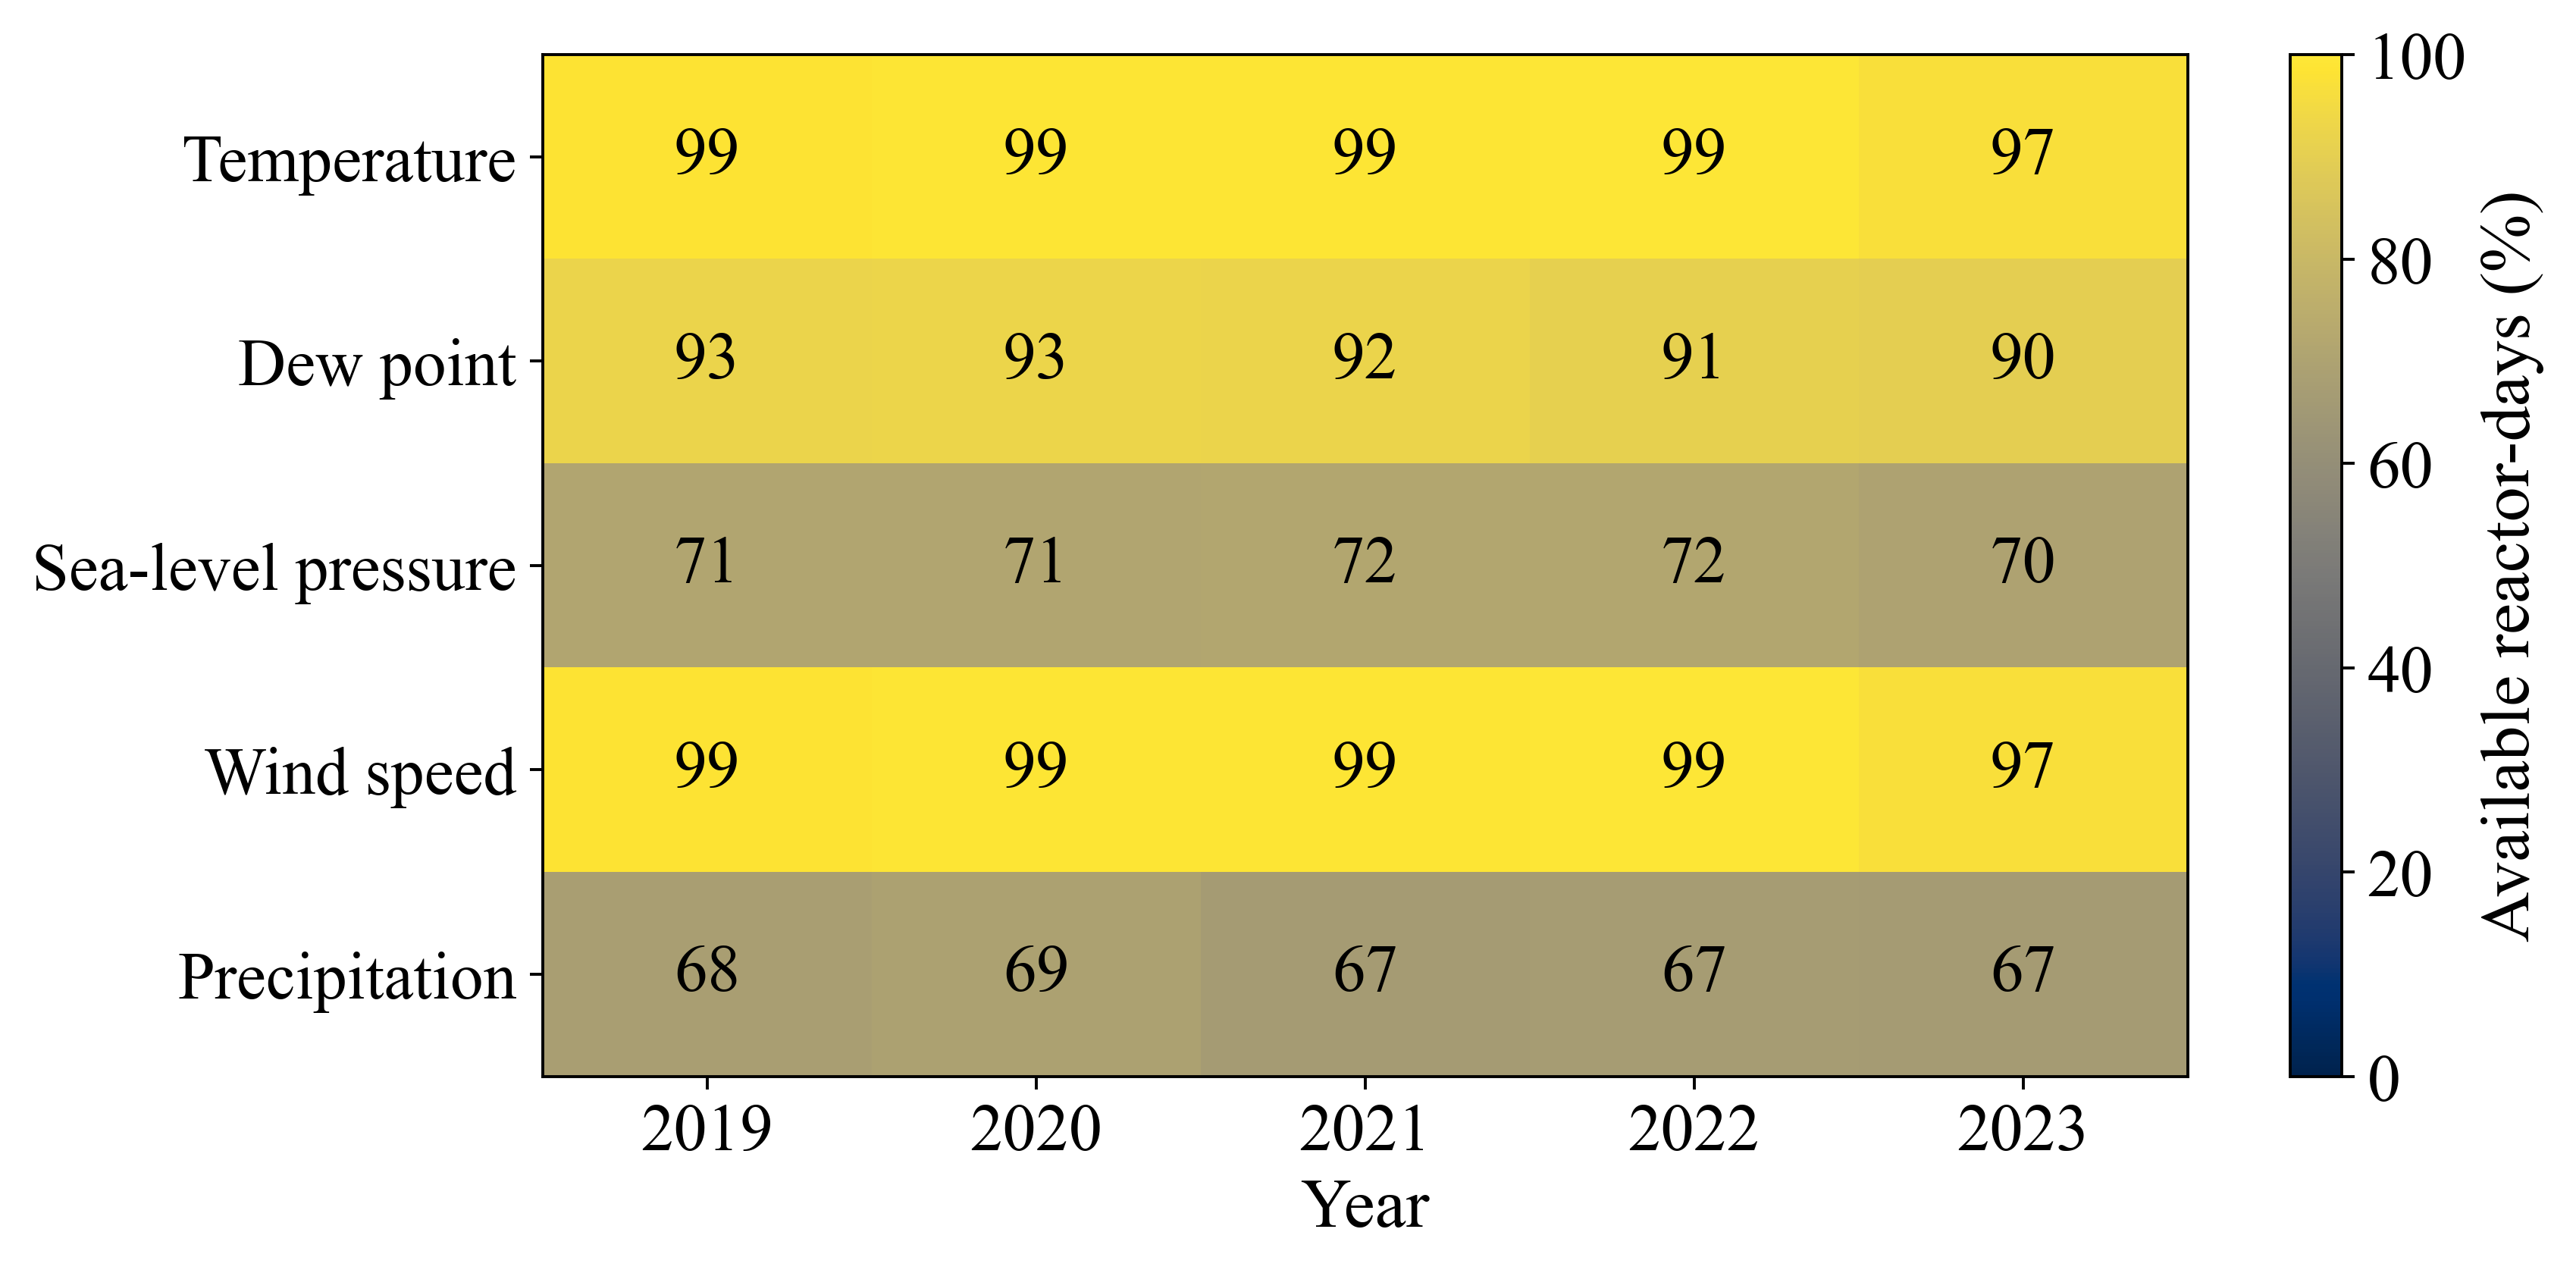

Weather availability after spatial matching and a three-day shift. Missing values are not replaced by zeros. The shift is an assumed publication lag, not proof of historical availability of every revised archive value.

In [15]:
selected_weather = selected_stations[["eia_plant_code", "station_id", "distance_km"]].merge(weather_data, on="station_id", how="left", validate="many_to_many")
selected_weather["date"] = selected_weather.weather_date + pd.Timedelta(days=3)
assert not selected_weather.duplicated(["eia_plant_code", "date"]).any()
power = power.drop(columns=[c for c in ["station_id", "distance_km", "weather_date", *weather_variables, "weather_missing_fraction"] if c in power]).merge(selected_weather, on=["eia_plant_code", "date"], how="left", validate="many_to_one")
power["weather_missing_fraction"] = power[weather_variables].isna().mean(axis=1)
assert (power.weather_date.dropna() < power.loc[power.weather_date.notna(), "date"]).all()
dev_power = power.loc[power.date.lt("2024-01-01")].copy()
coverage_year = dev_power.assign(year=dev_power.date.dt.year).groupby("year")[weather_variables].agg(lambda x: 100*x.notna().mean())
fig, ax = plt.subplots(figsize=(10, 5))
values = coverage_year.to_numpy().T
im = ax.imshow(values, vmin=0, vmax=100, cmap="cividis", aspect="auto")
ax.set_xticks(range(len(coverage_year)), coverage_year.index.astype(str))
ax.set_yticks(range(5), ["Temperature", "Dew point", "Sea-level pressure", "Wind speed", "Precipitation"])
ax.set_xlabel("Year")
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        ax.text(col, row, f"{values[row,col]:.0f}", ha="center", va="center", color="black" if values[row,col]>55 else "white", fontsize=18)
fig.colorbar(im, ax=ax, label="Available reactor-days (%)")
publication_figure(fig, "nb01_weather_availability", coverage_year.reset_index(),
    "Weather availability after spatial matching and a three-day shift. Missing values are not replaced by zeros. The shift is an assumed publication lag, not proof of historical availability of every revised archive value.")

## Independent structured NRC events

In [16]:
scram_registry["event_date"] = pd.to_datetime(scram_registry["Date"]).dt.normalize()
scram_registry["reactor_id"] = scram_registry.Docket.map(normalize_docket)
scram_registry["event_id"] = scram_registry.Event_Notification_Number.astype(int).astype(str)
curated_events = scram_registry.loc[scram_registry.event_date.between("2019-01-01", "2025-12-31")].copy()
assert curated_events.event_date.notna().all()
curated_dev = curated_events.loc[curated_events.event_date.lt("2024-01-01")]
label_coverage = curated_dev.groupby(curated_dev.event_date.dt.year).agg(
    reactor_events=("event_id", "size"), notifications=("event_id", "nunique"), reactors=("reactor_id", "nunique"),
    automatic=("Auto/Manual", lambda s: s.eq("A").sum()), manual=("Auto/Manual", lambda s: s.eq("M").sum()),
    retract_flag=("NRC_retract_flag", "sum")).reset_index(names="Year")
scientific_table(label_coverage, "nb01_curated_label_coverage", "Independent curated labels in the development pool")

**Independent curated labels in the development pool**

Year,reactor_events,notifications,reactors,automatic,manual,retract_flag
2019,50,50,40,27,23,2
2020,47,47,32,27,20,0
2021,37,37,28,23,14,0
2022,37,37,28,20,17,2
2023,43,43,31,31,12,0


In [17]:
def structured_value(box, label: str) -> str:
    """Read one labelled structured value; never enter the narrative section."""
    field = next((b for b in box.find_all("b") if b.get_text(" ", strip=True).rstrip(":") == label), None)
    if field is None:
        return ""
    tokens = []
    for sibling in field.next_siblings:
        if getattr(sibling, "name", None) in {"br", "b"}:
            break
        tokens.append(sibling.get_text(" ", strip=True) if hasattr(sibling, "get_text") else str(sibling))
    return " ".join(tokens).strip()


def parse_event_page(file: Path) -> list[dict]:
    soup = BeautifulSoup(file.read_bytes(), "html.parser")
    records = []
    for box in soup.select("div.grid.border[id]"):
        heading = box.find("div", class_="th")
        if heading is None or heading.get_text(strip=True) != "Power Reactor":
            continue
        unit_table = None
        for sibling in box.next_siblings:
            if getattr(sibling, "name", None) == "div" and sibling.get("id", "").startswith("en"):
                break
            if getattr(sibling, "name", None) == "table":
                unit_table = sibling
                break
        if unit_table is None or "SCRAM Code" not in unit_table.get_text():
            continue
        fields = {label: structured_value(box, label) for label in
                  ["Facility", "State", "Event Date", "Event Time", "Notification Date", "Notification Time", "Last Update Date"]}
        regulatory = box.get_text(" ", strip=True)
        for tr in unit_table.select("tbody tr"):
            values = [td.get_text(" ", strip=True) for td in tr.find_all("td")]
            if len(values) != 7:
                continue
            records.append({**fields, "event_id": box["id"].removeprefix("en"), "unit_number": values[0],
                "scram_code": values[1], "critical": values[2], "initial_power": values[3],
                "initial_mode": values[4], "current_power": values[5], "current_mode": values[6],
                "rps_critical_category": "50.72(b)(2)(iv)(B)" in regulatory,
                "publication_date": pd.to_datetime(file.stem[:8], format="%Y%m%d"),
                "source_id": str(file.relative_to(SHARED_DATASET_ROOT))})
    return records


In [18]:
event_records = []
for year in range(2019, 2026):
    files = sorted((SHARED_DATASET_ROOT / f"Raw/NRC_Scrams/Event_Notifications/{year}").glob("*.html"))
    assert files, f"No local archive for {year}"
    for file in files:
        event_records.extend(parse_event_page(file))


In [19]:
notifications = pd.DataFrame(event_records)
for source_name, target_name in [("Event Date", "event_date"), ("Notification Date", "notification_date"), ("Last Update Date", "update_date")]:
    notifications[target_name] = pd.to_datetime(notifications[source_name], format="%m/%d/%Y", errors="coerce")
assert notifications.event_date.notna().all()
notifications["initial_power"] = pd.to_numeric(notifications.initial_power, errors="coerce")
notifications["current_power"] = pd.to_numeric(notifications.current_power, errors="coerce")
notifications["facility_key"] = notifications.Facility.map(normalize_name).replace({"arkansasnuclear":"ano", "arkansasnuclearone":"ano", "columbia":"columbiageneratingstation", "harris":"shearonharris", "stlucie":"saintlucie", "riverbendstation":"riverbend", "cook":"dccook", "ftcalhoun":"fortcalhoun", "vogtle34":"vogtle", "vogtle12":"vogtle"})
lookup = dict(zip(unit_mapping.name_key, unit_mapping.reactor_id))
lookup.update(dict(zip(reactor_registry.name_key, reactor_registry.reactor_id)))
def notification_reactor(row):
    with_unit = row.facility_key + re.sub(r"\D", "", str(row.unit_number))
    return lookup.get(with_unit, lookup.get(row.facility_key, None))
notifications["reactor_id"] = notifications.apply(notification_reactor, axis=1)
notification_keys = ["event_id", "unit_number", "event_date"]
notification_conflicts = notifications.groupby(notification_keys).scram_code.nunique().gt(1).rename("code_conflict")
notifications = notifications.sort_values(["update_date", "publication_date"]).drop_duplicates(notification_keys, keep="last").merge(notification_conflicts, on=notification_keys, validate="one_to_one")
notifications.to_parquet(SHARED_DATASET_ROOT / "Processed/nrc_structured_notifications.parquet", index=False)
notification_dev = notifications.loc[notifications.event_date.between("2019-01-01", "2023-12-31")]
notification_quality = notification_dev.groupby(notification_dev.event_date.dt.year).agg(
    unit_notifications=("event_id", "size"), matched_units=("reactor_id", "count"),
    code_conflicts=("code_conflict", "sum"), distinct_events=("event_id", "nunique")).reset_index(names="Year")
scientific_table(notification_quality, "nb01_notification_quality", "Structured archive notifications and matching completeness")
unmatched = notification_dev.loc[notification_dev.reactor_id.isna(), ["Facility", "State", "unit_number"]].drop_duplicates()
unmatched.to_csv(TABLES / "nb01_notification_unmatched.csv", index=False)
if len(unmatched):
    scientific_table(unmatched, "nb01_notification_unmatched", "Unmatched archive units remain excluded until identity is resolved")

**Structured archive notifications and matching completeness**

Year,unit_notifications,matched_units,code_conflicts,distinct_events
2019,299,299,0,236
2020,252,252,0,191
2021,219,219,0,171
2022,215,215,0,171
2023,245,245,0,198


## Target definition and control cohort

In [20]:
curated_labels = curated_events[["reactor_id", "event_date", "event_id", "Auto/Manual", "NRC_retract_flag"]].rename(columns={"Auto/Manual":"scram_type", "NRC_retract_flag":"retract_flag"})
curated_labels["label_source"] = "NRC curated SCRAM"
archive_scrams = notifications.loc[notifications.scram_code.isin(["A/R", "M/R"]) & (notifications.critical.eq("Y") | notifications.rps_critical_category) & ~notifications.code_conflict & notifications.reactor_id.notna()].copy()
archive_scrams["scram_type"] = archive_scrams.scram_code.str[0]
archive_scrams["retract_flag"] = pd.NA
archive_scrams["label_source"] = "NRC structured SCRAM"
positive_events = pd.concat([curated_labels, archive_scrams[curated_labels.columns]], ignore_index=True).drop_duplicates(["reactor_id", "event_id"], keep="first")
positive_events = positive_events.loc[positive_events.event_date.between("2019-01-01", "2025-12-31")].sort_values(["reactor_id", "event_date", "event_id"])
positive_events["date"] = positive_events.event_date + pd.Timedelta(days=1)
positive_events["episode_start"] = positive_events.groupby("reactor_id").event_date.diff().dt.days.gt(7) | positive_events.groupby("reactor_id").event_date.diff().isna()
positive_events["episode_index"] = positive_events.groupby("reactor_id").episode_start.cumsum()
positive_events["event_episode_id"] = positive_events.reactor_id + "_event_" + positive_events.episode_index.astype(str)
positive_days = positive_events.groupby(["reactor_id", "date"]).agg(event_id=("event_id", lambda s:";".join(sorted(set(s)))),
    event_episode_id=("event_episode_id", "first"), label_source=("label_source", lambda s:";".join(sorted(set(s)))),
    scram_type=("scram_type", lambda s:";".join(sorted(set(s))))).reset_index()
assert not positive_days.duplicated(["reactor_id", "date"]).any()
positive_events.to_parquet(SHARED_DATASET_ROOT / "Processed/nrc_confirmed_reactor_events.parquet", index=False)
observations = power.merge(positive_days, on=["reactor_id", "date"], how="left", validate="one_to_one")
observations["confirmed_scram"] = observations.event_id.notna()
non_scram = notifications.loc[notifications.scram_code.eq("N") & ~notifications.code_conflict & notifications.reactor_id.notna(), ["reactor_id", "event_date", "event_id"]].copy()
non_scram["date"] = non_scram.event_date + pd.Timedelta(days=1)
non_scram_days = non_scram.groupby(["reactor_id", "date"]).event_id.agg(lambda s:";".join(sorted(set(s)))).rename("non_scram_event_id").reset_index()
observations = observations.merge(non_scram_days, on=["reactor_id", "date"], how="left", validate="one_to_one")


In [21]:
observations = observations.sort_values(["reactor_id", "date"]).reset_index(drop=True)
grouped = observations.groupby("reactor_id", sort=False)
observations["window_7_range"] = grouped.power_pct.transform(lambda s:s.rolling(7, min_periods=7).max()-s.rolling(7, min_periods=7).min())
observations["window_7_span"] = grouped.date.transform(lambda s:s.diff(6).dt.days)
observations["stable_control_candidate"] = observations.window_7_span.eq(6) & observations.window_7_range.le(2)
observations["near_confirmed_event"] = False
for reactor_id, indices in observations.groupby("reactor_id", sort=False).groups.items():
    candidate_dates = notifications.loc[notifications.reactor_id.eq(reactor_id) & notifications.scram_code.isin(["A/R", "M/R"]), "event_date"] + pd.Timedelta(days=1)
    event_dates = pd.concat([positive_days.loc[positive_days.reactor_id.eq(reactor_id), "date"], candidate_dates]).drop_duplicates().to_numpy(dtype="datetime64[D]")
    dates = observations.loc[indices, "date"].to_numpy(dtype="datetime64[D]")
    if len(event_dates):
        nearest_days = np.abs((dates[:, None]-event_dates[None, :]).astype("timedelta64[D]").astype(int)).min(axis=1)
        observations.loc[indices, "near_confirmed_event"] = nearest_days <= 7
observations["documented_control_candidate"] = observations.non_scram_event_id.notna()
control = (observations.stable_control_candidate | observations.documented_control_candidate) & ~observations.near_confirmed_event
observations["target"] = pd.Series(pd.NA, index=observations.index, dtype="Int64")
observations.loc[control, "target"] = 0
observations.loc[observations.confirmed_scram, "target"] = 1
observations["control_kind"] = np.select([observations.documented_control_candidate, observations.stable_control_candidate], ["Documented non-SCRAM", "Stable observed regime"], default="Uncertain")
observations.loc[observations.confirmed_scram, "control_kind"] = "Confirmed SCRAM"
observations.loc[control, "label_source"] = observations.loc[control, "control_kind"]
regime_boundary = observations.regime.ne(observations.groupby("reactor_id").regime.shift()) | observations.day_gap.ne(1)
regime_index = regime_boundary.groupby(observations.reactor_id).cumsum()
observations["episode_id"] = observations.event_episode_id.fillna(observations.reactor_id + "_regime_" + regime_index.astype(str))
observations["split"] = np.select([observations.date.lt("2023-01-01"), observations.date.lt("2024-01-01"), observations.date.lt("2025-01-01")], ["train", "development", "calibration"], default="locked_test")
# Reported zeros after a documented permanent shutdown are outside the operational cohort.
retirement_dates = decommissioning.assign(reactor_id=decommissioning["Docket Number"].map(normalize_docket), shutdown_date=pd.to_datetime(decommissioning["Shut Down"], errors="coerce")).set_index("reactor_id").shutdown_date
observations["recorded_shutdown_date"] = observations.reactor_id.map(retirement_dates)
observations["after_recorded_shutdown"] = observations.date.gt(observations.recorded_shutdown_date + pd.Timedelta(days=1))
observations["eligible"] = observations.target.notna() & observations.power_pct.notna() & ~observations.after_recorded_shutdown
development_cohort = observations.loc[observations.split.isin(["train", "development"])].copy()
cohort_summary = development_cohort.groupby(["source_year", "control_kind"]).agg(n=("observation_id", "size"),
    eligible=("eligible", "sum"), sites=("plant_id", "nunique")).reset_index()
for year, group in cohort_summary.groupby("source_year"):
    scientific_table(group, f"nb01_cohort_{year}", f"Cohort composition, {year}; uncertain observations do not become negatives")

**Cohort composition, 2019; uncertain observations do not become negatives**

source_year,control_kind,n,eligible,sites
2019,Confirmed SCRAM,51,51,35
2019,Documented non-SCRAM,229,217,50
2019,Stable observed regime,30495,30058,58
2019,Uncertain,4945,0,58


**Cohort composition, 2020; uncertain observations do not become negatives**

source_year,control_kind,n,eligible,sites
2020,Confirmed SCRAM,47,47,28
2020,Documented non-SCRAM,194,186,50
2020,Stable observed regime,30232,29224,56
2020,Uncertain,5029,0,55


**Cohort composition, 2021; uncertain observations do not become negatives**

source_year,control_kind,n,eligible,sites
2021,Confirmed SCRAM,37,37,25
2021,Documented non-SCRAM,165,163,47
2021,Stable observed regime,30283,29481,56
2021,Uncertain,4164,0,54


**Cohort composition, 2022; uncertain observations do not become negatives**

source_year,control_kind,n,eligible,sites
2022,Confirmed SCRAM,37,37,25
2022,Documented non-SCRAM,163,158,46
2022,Stable observed regime,29530,29307,53
2022,Uncertain,4098,0,51


**Cohort composition, 2023; uncertain observations do not become negatives**

source_year,control_kind,n,eligible,sites
2023,Confirmed SCRAM,43,43,27
2023,Documented non-SCRAM,188,185,48
2023,Stable observed regime,29614,29368,52
2023,Uncertain,4233,0,51


In [22]:
matched_positive = development_cohort.loc[development_cohort.target.eq(1).fillna(False)]
positive_adequacy = matched_positive.groupby("source_year").agg(reactor_event_days=("observation_id", "size"),
    event_episode_clusters=("episode_id", "nunique"), sites=("plant_id", "nunique")).reset_index()
scientific_table(positive_adequacy, "nb01_positive_adequacy", "Positive days, episodes and sites; days are not independent events")
subtype_counts = pd.crosstab(matched_positive.source_year, matched_positive.scram_type).reset_index()
scientific_table(subtype_counts, "nb01_scram_subtypes", "SCRAM subtype coverage; small classes limit multiclass analysis")
assert matched_positive.loc[matched_positive.split.eq("train"), "episode_id"].nunique() >= 40
assert matched_positive.loc[matched_positive.split.eq("development"), "episode_id"].nunique() >= 20


**Positive days, episodes and sites; days are not independent events**

source_year,reactor_event_days,event_episode_clusters,sites
2019,51,50,35
2020,47,45,28
2021,37,36,25
2022,37,37,25
2023,43,43,27


**SCRAM subtype coverage; small classes limit multiclass analysis**

source_year,A,M
2019,27,24
2020,27,20
2021,23,14
2022,20,17
2023,31,12


## Label provenance and cohort heterogeneity

In [23]:
development_events = positive_events.loc[positive_events.event_date.lt("2024-01-01")].copy()
label_match = development_events.merge(power[["reactor_id", "date", "observation_id"]], on=["reactor_id", "date"], how="left", validate="many_to_one")
label_match["power_matched"] = label_match.observation_id.notna()
label_audit = label_match.groupby([label_match.event_date.dt.year.rename("Year"), "label_source"]).agg(events=("event_id", "size"), matched_power=("power_matched", "sum")).reset_index()
scientific_table(label_audit, "nb01_label_provenance", "Source of independent confirmation and availability of the next power report")
archive_dev = archive_scrams.loc[archive_scrams.event_date.between("2019-01-01", "2023-12-31")]
agreement = curated_dev.merge(archive_dev[["reactor_id", "event_date", "event_id", "scram_code"]], on=["reactor_id", "event_date", "event_id"], how="left", validate="one_to_one")
agreement["archive_agreement"] = agreement.scram_code.str[0].eq(agreement["Auto/Manual"])
scientific_table(agreement.groupby(agreement.event_date.dt.year).agg(curated_events=("event_id", "size"), matched_archive_type=("archive_agreement", "sum")).reset_index(names="Year"), "nb01_label_agreement", "Agreement between curated SCRAM records and structured archive types")
retirement = decommissioning[["Unit", "Docket Number", "Shut Down"]].copy()
retirement["reactor_id"] = retirement["Docket Number"].map(normalize_docket)
retirement["shutdown_date"] = pd.to_datetime(retirement["Shut Down"], errors="coerce")
retirement_audit = retirement.merge(dev_power.groupby("reactor_id").date.agg(["min", "max"]).reset_index(), on="reactor_id", how="inner")
scientific_table(retirement_audit[["Unit", "shutdown_date", "min", "max"]], "nb01_retirement_overlap", "Retired units represented in historical reports; reporting dates do not define operating lifetime")
all_archive_match = curated_dev.merge(notifications[["reactor_id", "event_date", "event_id", "scram_code", "critical", "rps_critical_category"]], on=["reactor_id", "event_date", "event_id"], how="left", validate="one_to_one")
review_mask = ~all_archive_match.event_id.isin(agreement.loc[agreement.archive_agreement, "event_id"])
scientific_table(all_archive_match.loc[review_mask, ["Plant Name", "event_date", "event_id", "Auto/Manual", "scram_code", "critical", "rps_critical_category"]].fillna("Archive match absent"), "nb01_label_discrepancies", "Curated SCRAM records without a matching archive criterion. Archive match absent means no matching archive row by reactor/date/event ID; curated labels retain priority")

**Source of independent confirmation and availability of the next power report**

Year,label_source,events,matched_power
2019,NRC curated SCRAM,50,50
2019,NRC structured SCRAM,2,2
2020,NRC curated SCRAM,47,47
2021,NRC curated SCRAM,37,37
2021,NRC structured SCRAM,1,1
2022,NRC curated SCRAM,37,37
2023,NRC curated SCRAM,43,43
2023,NRC structured SCRAM,1,1


**Agreement between curated SCRAM records and structured archive types**

Year,curated_events,matched_archive_type
2019,50,48
2020,47,46
2021,37,37
2022,37,36
2023,43,43


**Retired units represented in historical reports; reporting dates do not define operating lifetime**

Unit,shutdown_date,min,max
Oyster Creek,2018-09-17 00:00:00,2019-01-01 00:00:00,2019-03-18 00:00:00
Three Mile Island 1,2019-09-20 00:00:00,2019-01-01 00:00:00,2021-03-22 00:00:00
Indian Point 2,2020-04-30 00:00:00,2019-01-01 00:00:00,2021-09-28 00:00:00
Indian Point 3,2021-04-30 00:00:00,2019-01-01 00:00:00,2021-09-28 00:00:00
Duane Arnold,2020-08-10 00:00:00,2019-01-01 00:00:00,2021-03-22 00:00:00


**Curated SCRAM records without a matching archive criterion. Archive match absent means no matching archive row by reactor/date/event ID; curated labels retain priority**

Plant Name,event_date,event_id,Auto/Manual,scram_code,critical,rps_critical_category
"Brunswick Steam Electric Plant, Unit 1",2019-03-28 00:00:00,53961,M,N,Y,False
Callaway Plant,2019-05-17 00:00:00,54069,A,Archive match absent,Archive match absent,Archive match absent
"Turkey Point Nuclear Generating Station, Unit 3",2020-08-19 00:00:00,54844,A,N,N,True
"North Anna Power Station, Unit 2",2022-08-27 00:00:00,56073,M,N,Y,False


In [24]:
source_agreement = curated_dev.merge(notification_dev[["reactor_id", "event_id", "event_date", "scram_code", "critical", "rps_critical_category"]].rename(columns={"event_date":"archive_date"}), on=["reactor_id", "event_id"], how="left", validate="one_to_many")
source_agreement["same_date"] = source_agreement.event_date.eq(source_agreement.archive_date)
scientific_table(source_agreement.loc[~source_agreement.same_date, ["Plant Name", "event_id", "event_date", "archive_date", "Auto/Manual", "scram_code"]], "nb01_label_date_discrepancy", "Date discrepancies for the same event; curated dates take priority")
archive_criteria = notification_dev.assign(code_present=notification_dev.scram_code.isin(["A/R", "M/R"]))
criteria_summary = archive_criteria.groupby(archive_criteria.event_date.dt.year).apply(lambda g: pd.Series({"SCRAM_code":int(g.code_present.sum()), "code_and_RPS_category":int((g.code_present & g.rps_critical_category).sum()), "code_and_RX_critical":int((g.code_present & g.critical.eq("Y")).sum()), "code_with_either_confirmation":int((g.code_present & (g.rps_critical_category | g.critical.eq("Y"))).sum())}), include_groups=False).reset_index(names="Year")
scientific_table(criteria_summary, "nb01_archive_criteria", "Sensitivity of structured archive labels to additional fields")

**Date discrepancies for the same event; curated dates take priority**

Plant Name,event_id,event_date,archive_date,Auto/Manual,scram_code
Callaway Plant,54069,2019-05-17 00:00:00,2019-05-16 00:00:00,A,A/R


**Sensitivity of structured archive labels to additional fields**

Year,SCRAM_code,code_and_RPS_category,code_and_RX_critical,code_with_either_confirmation
2019,51,48,50,50
2020,46,46,46,46
2021,39,37,33,38
2022,36,35,36,36
2023,44,43,43,44


## Temporal context of confirmed events

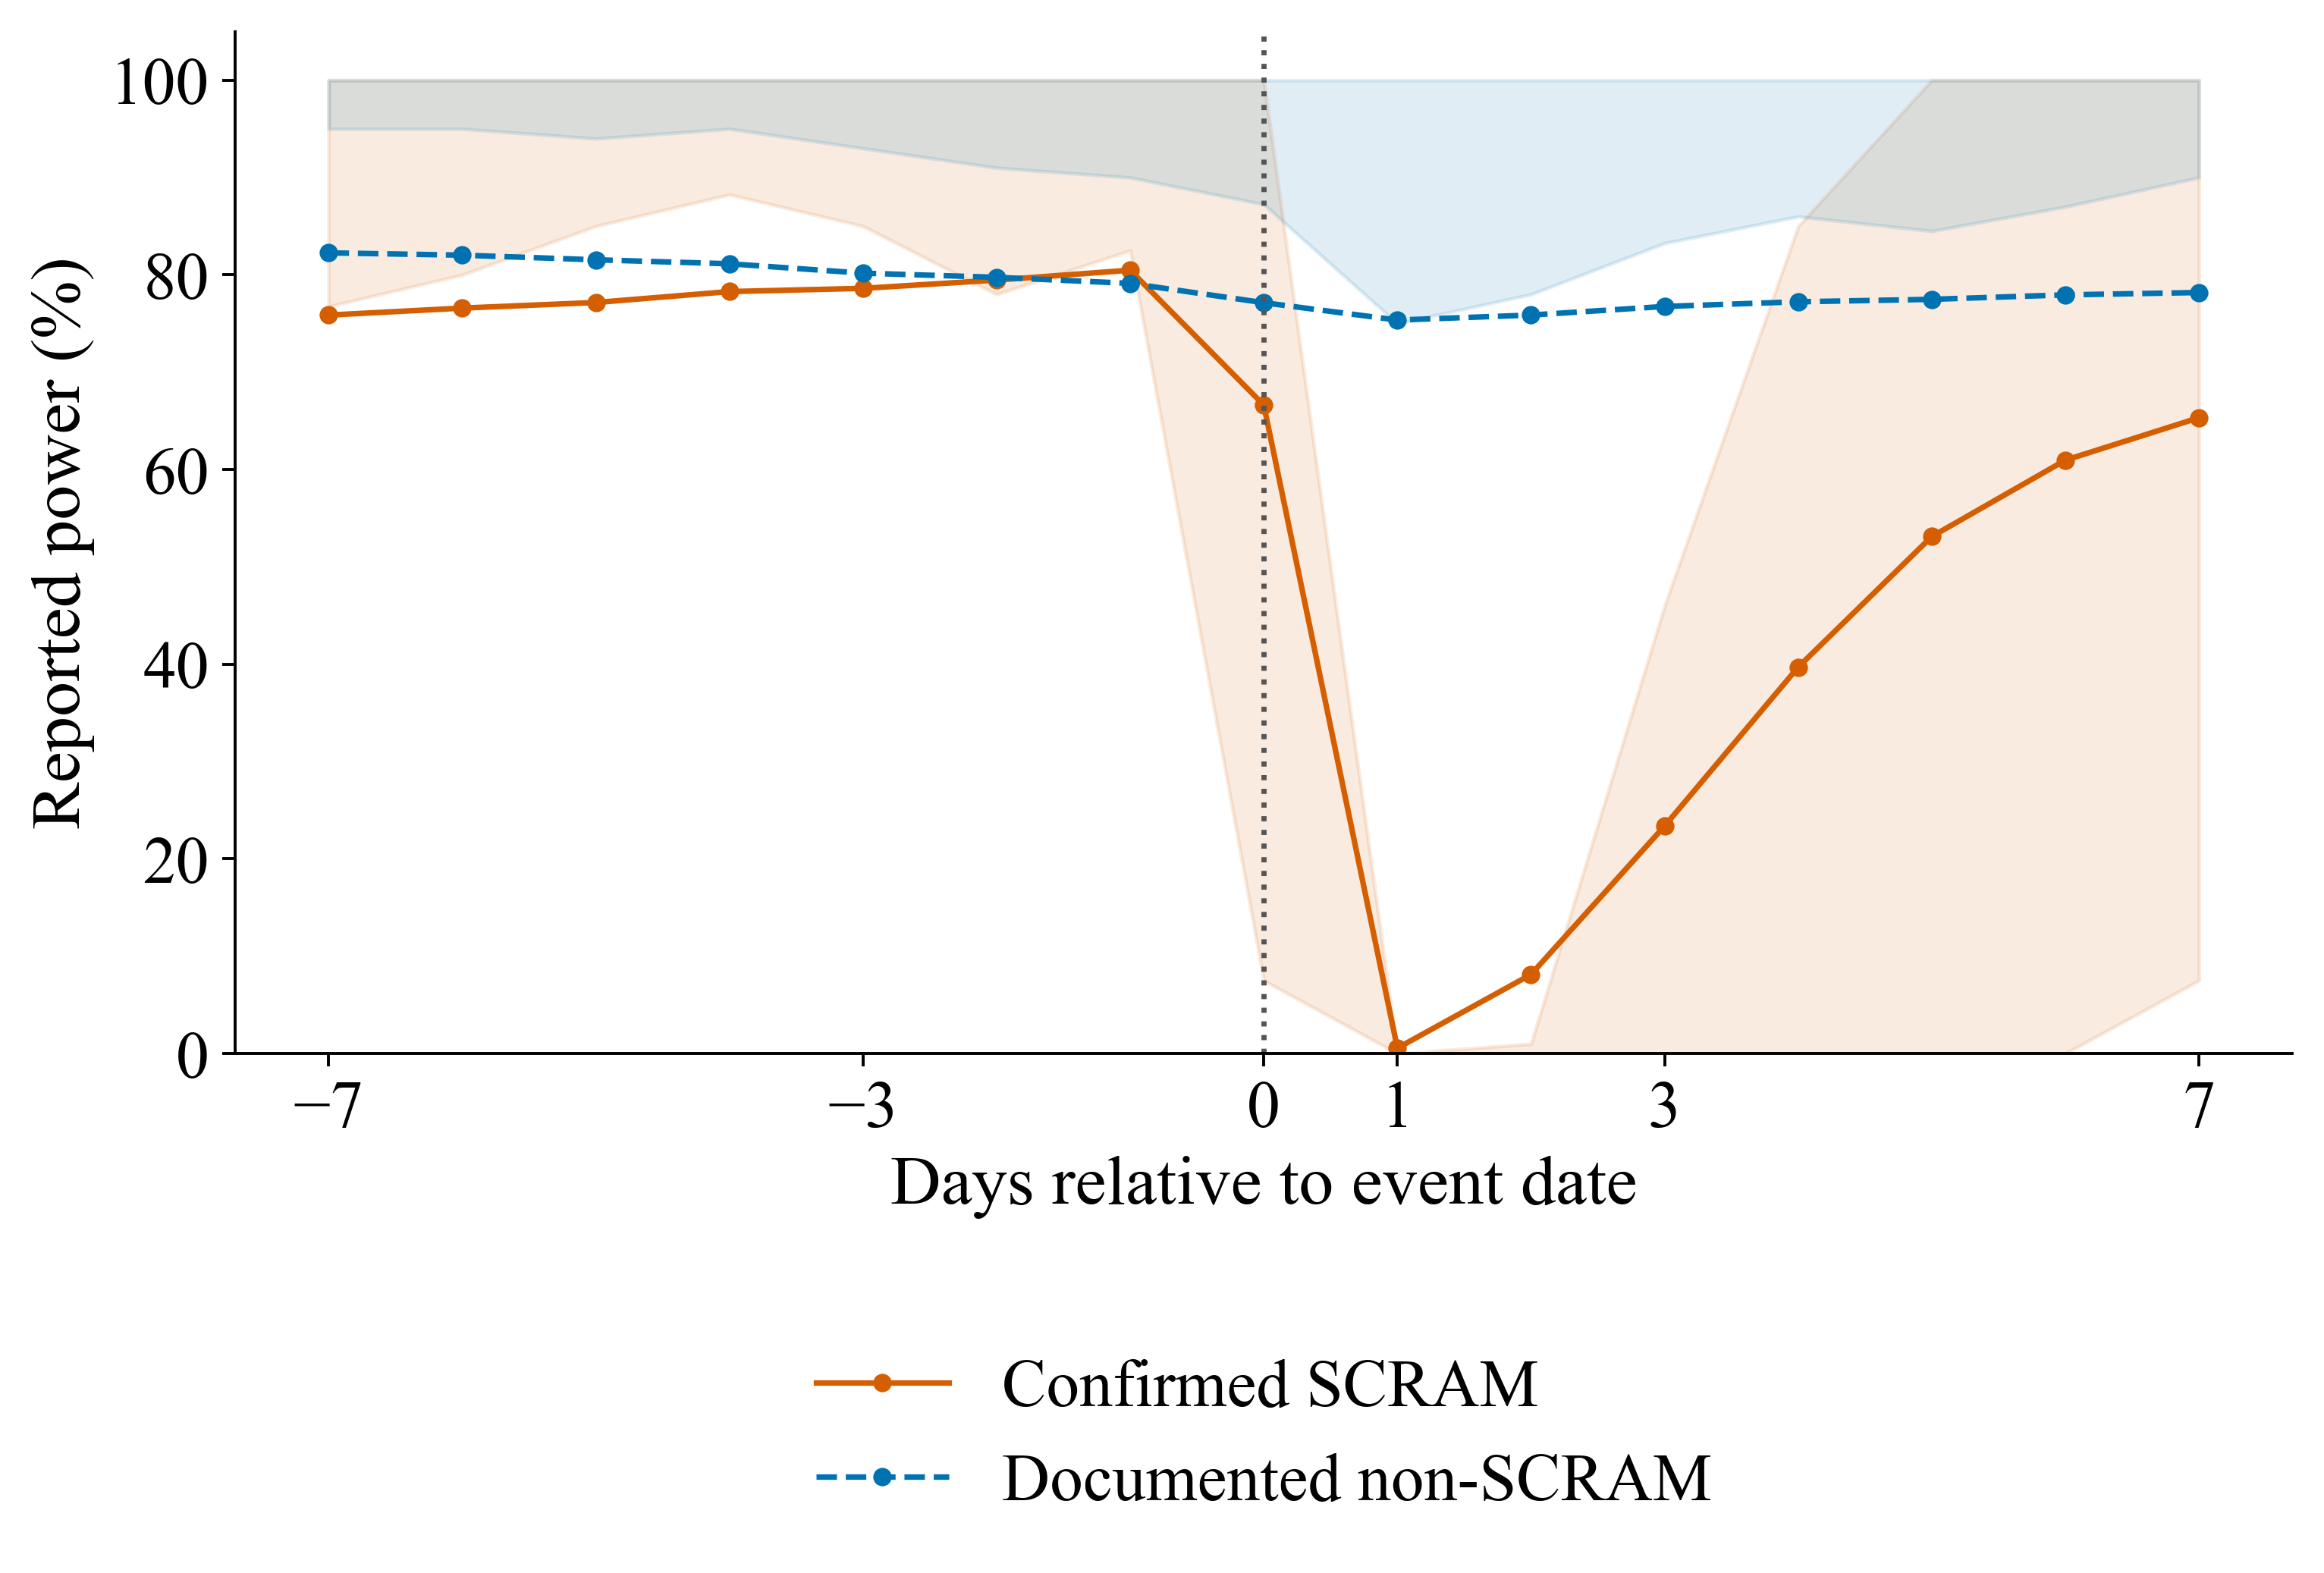

Mean power and interquartile variability aligned to structured event dates. Negative days precede the event; positive days follow it. This describes the signal, not model performance or forecasting ability.

In [25]:
aligned_parts = []
for label, events in [("Confirmed SCRAM", positive_events.loc[positive_events.event_date.lt("2024-01-01"), ["reactor_id", "event_date"]]),
    ("Documented non-SCRAM", non_scram.loc[non_scram.event_date.lt("2024-01-01"), ["reactor_id", "event_date"]])]:
    events = events.drop_duplicates()
    for lag in range(-7, 8):
        aligned = events.assign(date=events.event_date + pd.Timedelta(days=lag)).merge(
            dev_power[["reactor_id", "date", "power_pct"]], on=["reactor_id", "date"], how="left", validate="many_to_one")
        aligned_parts.append({"Class": label, "day_relative_to_event":lag, "n":aligned.power_pct.notna().sum(),
            "mean":aligned.power_pct.mean(), "q25":aligned.power_pct.quantile(.25), "q75":aligned.power_pct.quantile(.75)})
aligned_summary = pd.DataFrame(aligned_parts)
fig, ax = plt.subplots(figsize=(10, 5))
for label, color, style in [("Confirmed SCRAM", "#D55E00", "-"), ("Documented non-SCRAM", "#0072B2", "--")]:
    group = aligned_summary.loc[aligned_summary.Class.eq(label)]
    ax.plot(group.day_relative_to_event, group["mean"], color=color, ls=style, marker="o", markersize=4, label=label)
    ax.fill_between(group.day_relative_to_event, group.q25, group.q75, color=color, alpha=.12)
ax.axvline(0, color="#555555", ls=":", lw=1.4)
ax.set(xlabel="Days relative to event date", ylabel="Reported power (%)", ylim=(0, 105), xticks=[-7, -3, 0, 1, 3, 7])
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.24), ncol=1, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_event_alignment", aligned_summary,
    "Mean power and interquartile variability aligned to structured event dates. Negative days precede the event; positive days follow it. This describes the signal, not model performance or forecasting ability.")

## Distributions, reactor heterogeneity and temporal dependence

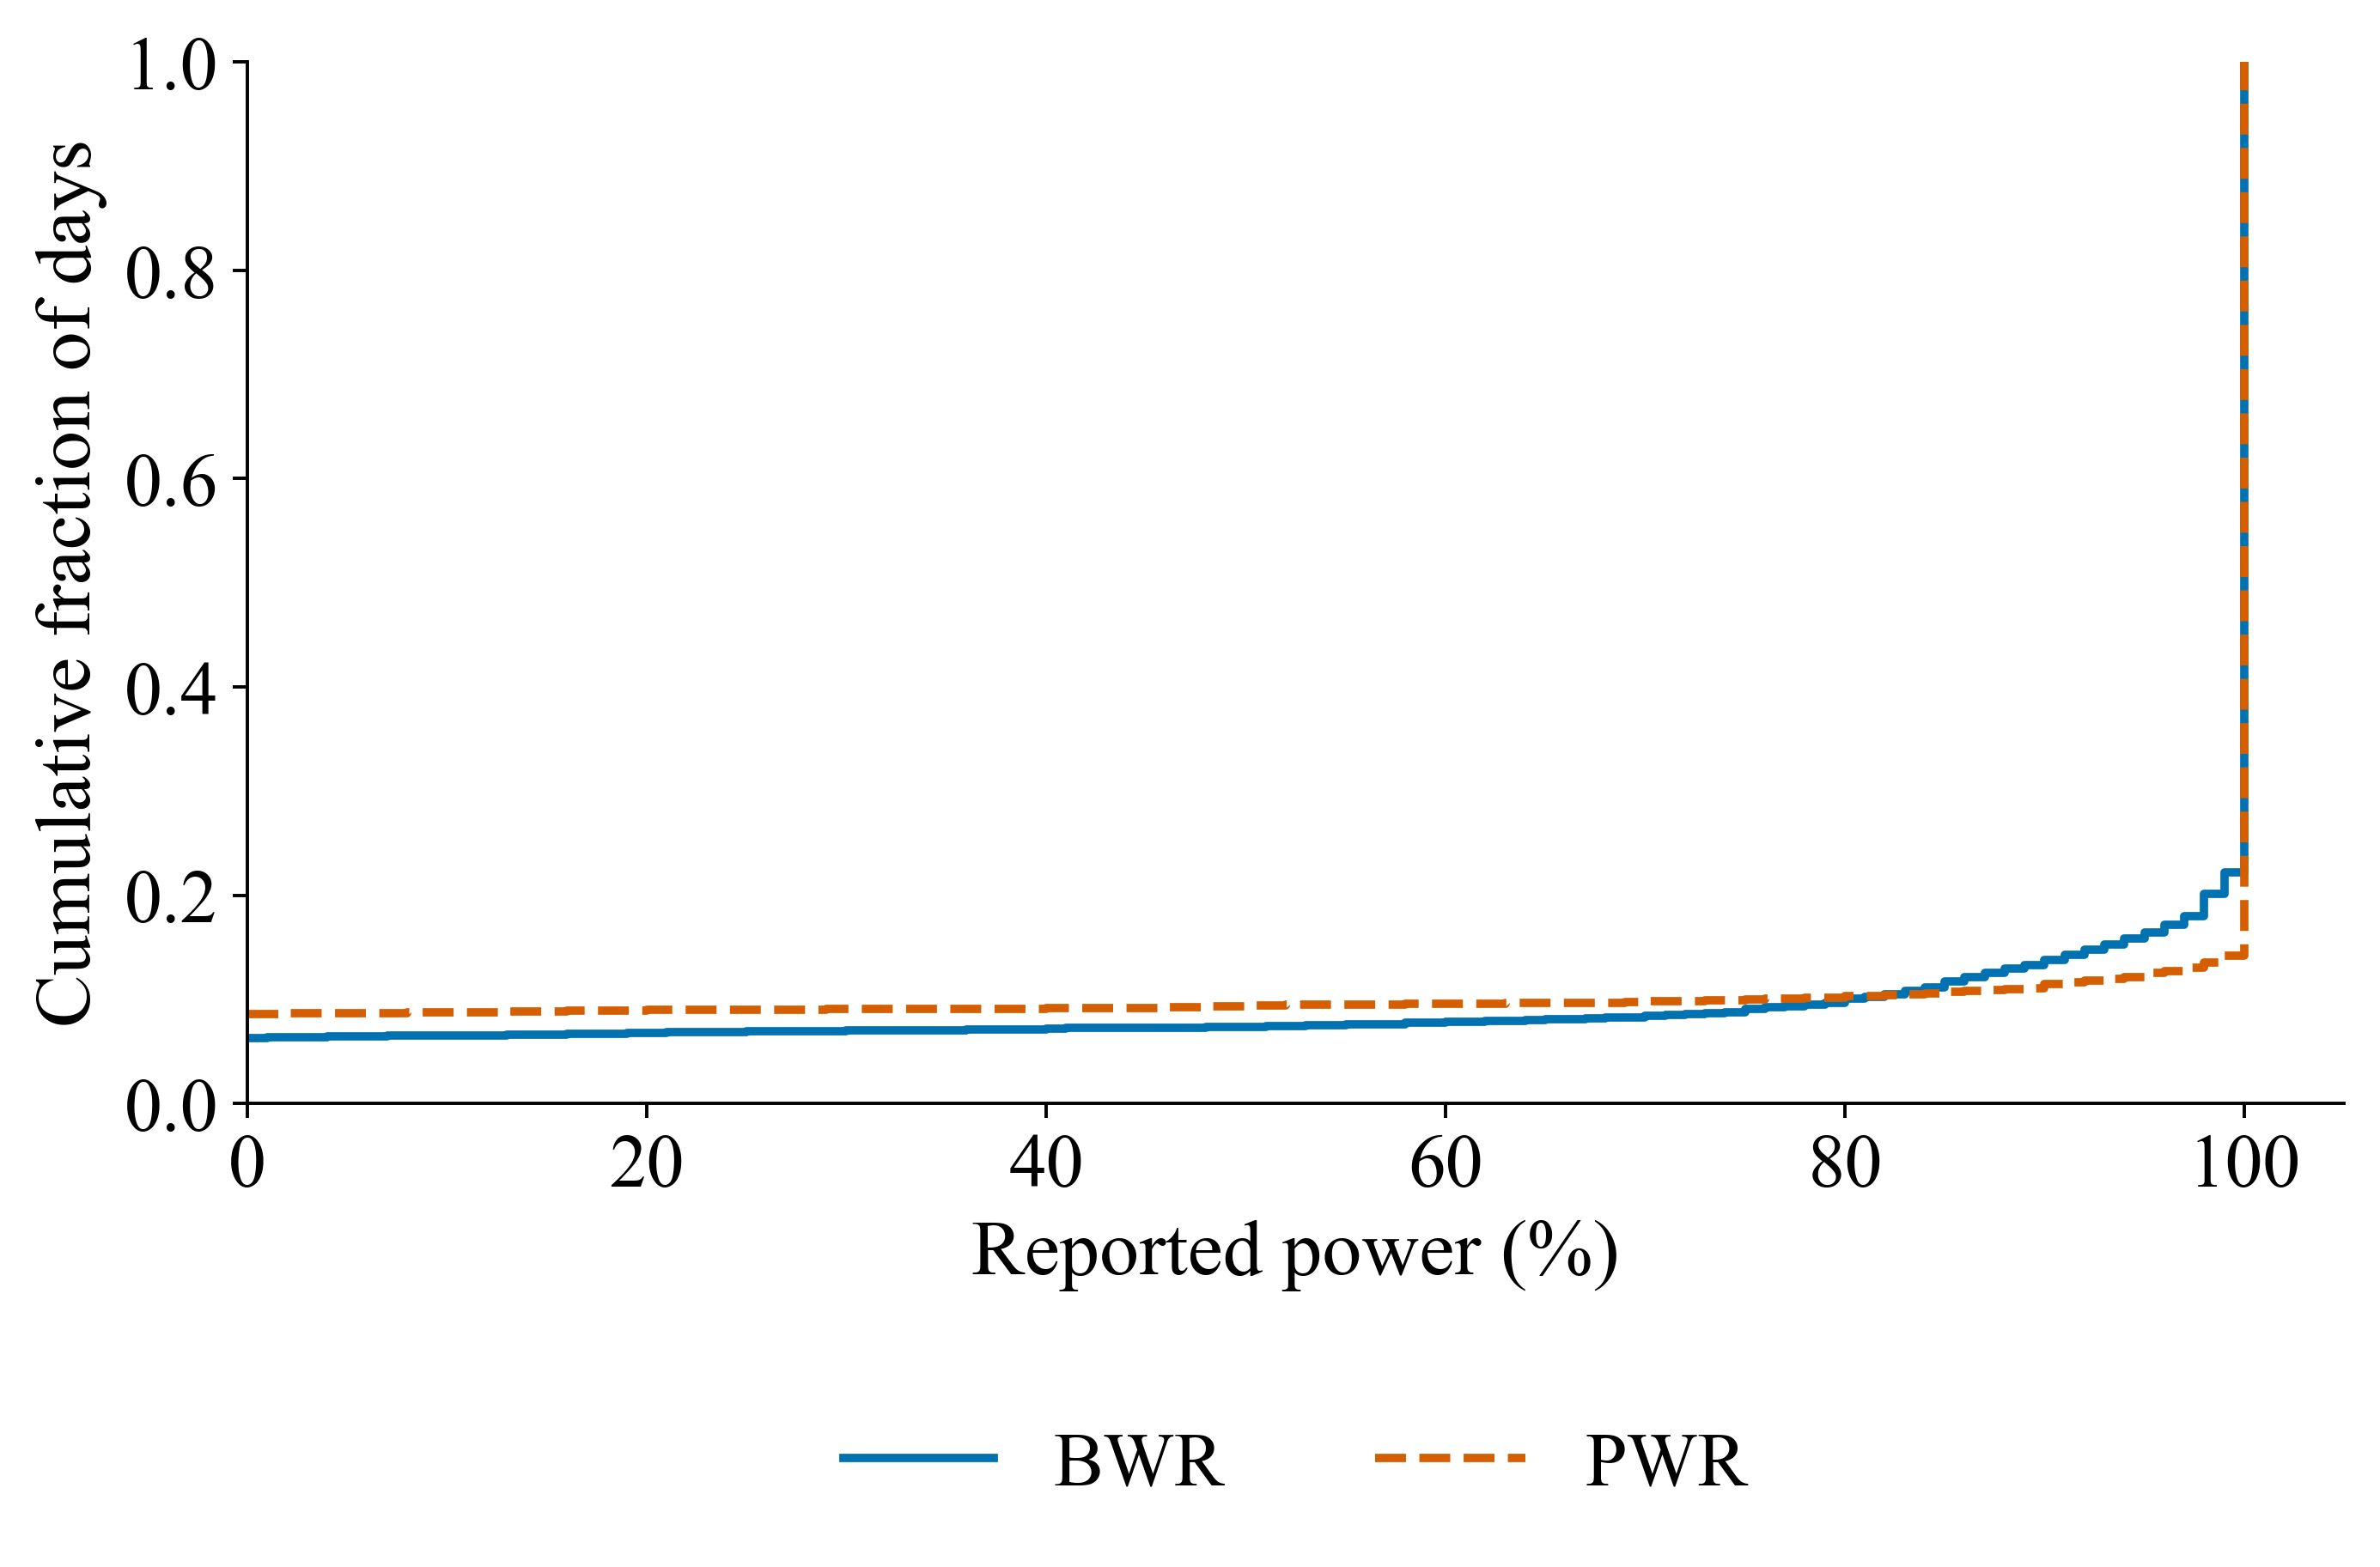

Empirical reported-power distributions by reactor type. The large jump at 100% illustrates why the median poorly describes shutdowns. Zero values are observed regimes, not missing measurements.

In [26]:
distribution_sources = []
fig, ax = plt.subplots(figsize=(9, 4.5))
for reactor_type, color, style in [("BWR", "#0072B2", "-"), ("PWR", "#D55E00", "--")]:
    counts = dev_power.loc[dev_power.reactor_type.eq(reactor_type), "power_pct"].value_counts().sort_index()
    distribution = counts.cumsum()/counts.sum()
    ax.step(distribution.index, distribution.values, where="post", color=color, ls=style, lw=2, label=reactor_type)
    distribution_sources.append(pd.DataFrame({"reactor_type":reactor_type, "power_pct":distribution.index, "cumulative_fraction":distribution.values, "n_at_power":counts.values}))
ax.set(xlabel="Reported power (%)", ylabel="Cumulative fraction of days", xlim=(0, 105), ylim=(0, 1))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.25), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_power_distribution", pd.concat(distribution_sources), "Empirical reported-power distributions by reactor type. The large jump at 100% illustrates why the median poorly describes shutdowns. Zero values are observed regimes, not missing measurements.")

**Between-reactor heterogeneity; reactors receive equal weight in the quartiles**

reactor_type,reactors,median_mean_power,q25_mean_power,q75_mean_power,median_zero_fraction
BWR,34,91.9723,89.8872,94.7425,0.0572
PWR,67,92.0465,89.7141,93.6914,0.0690


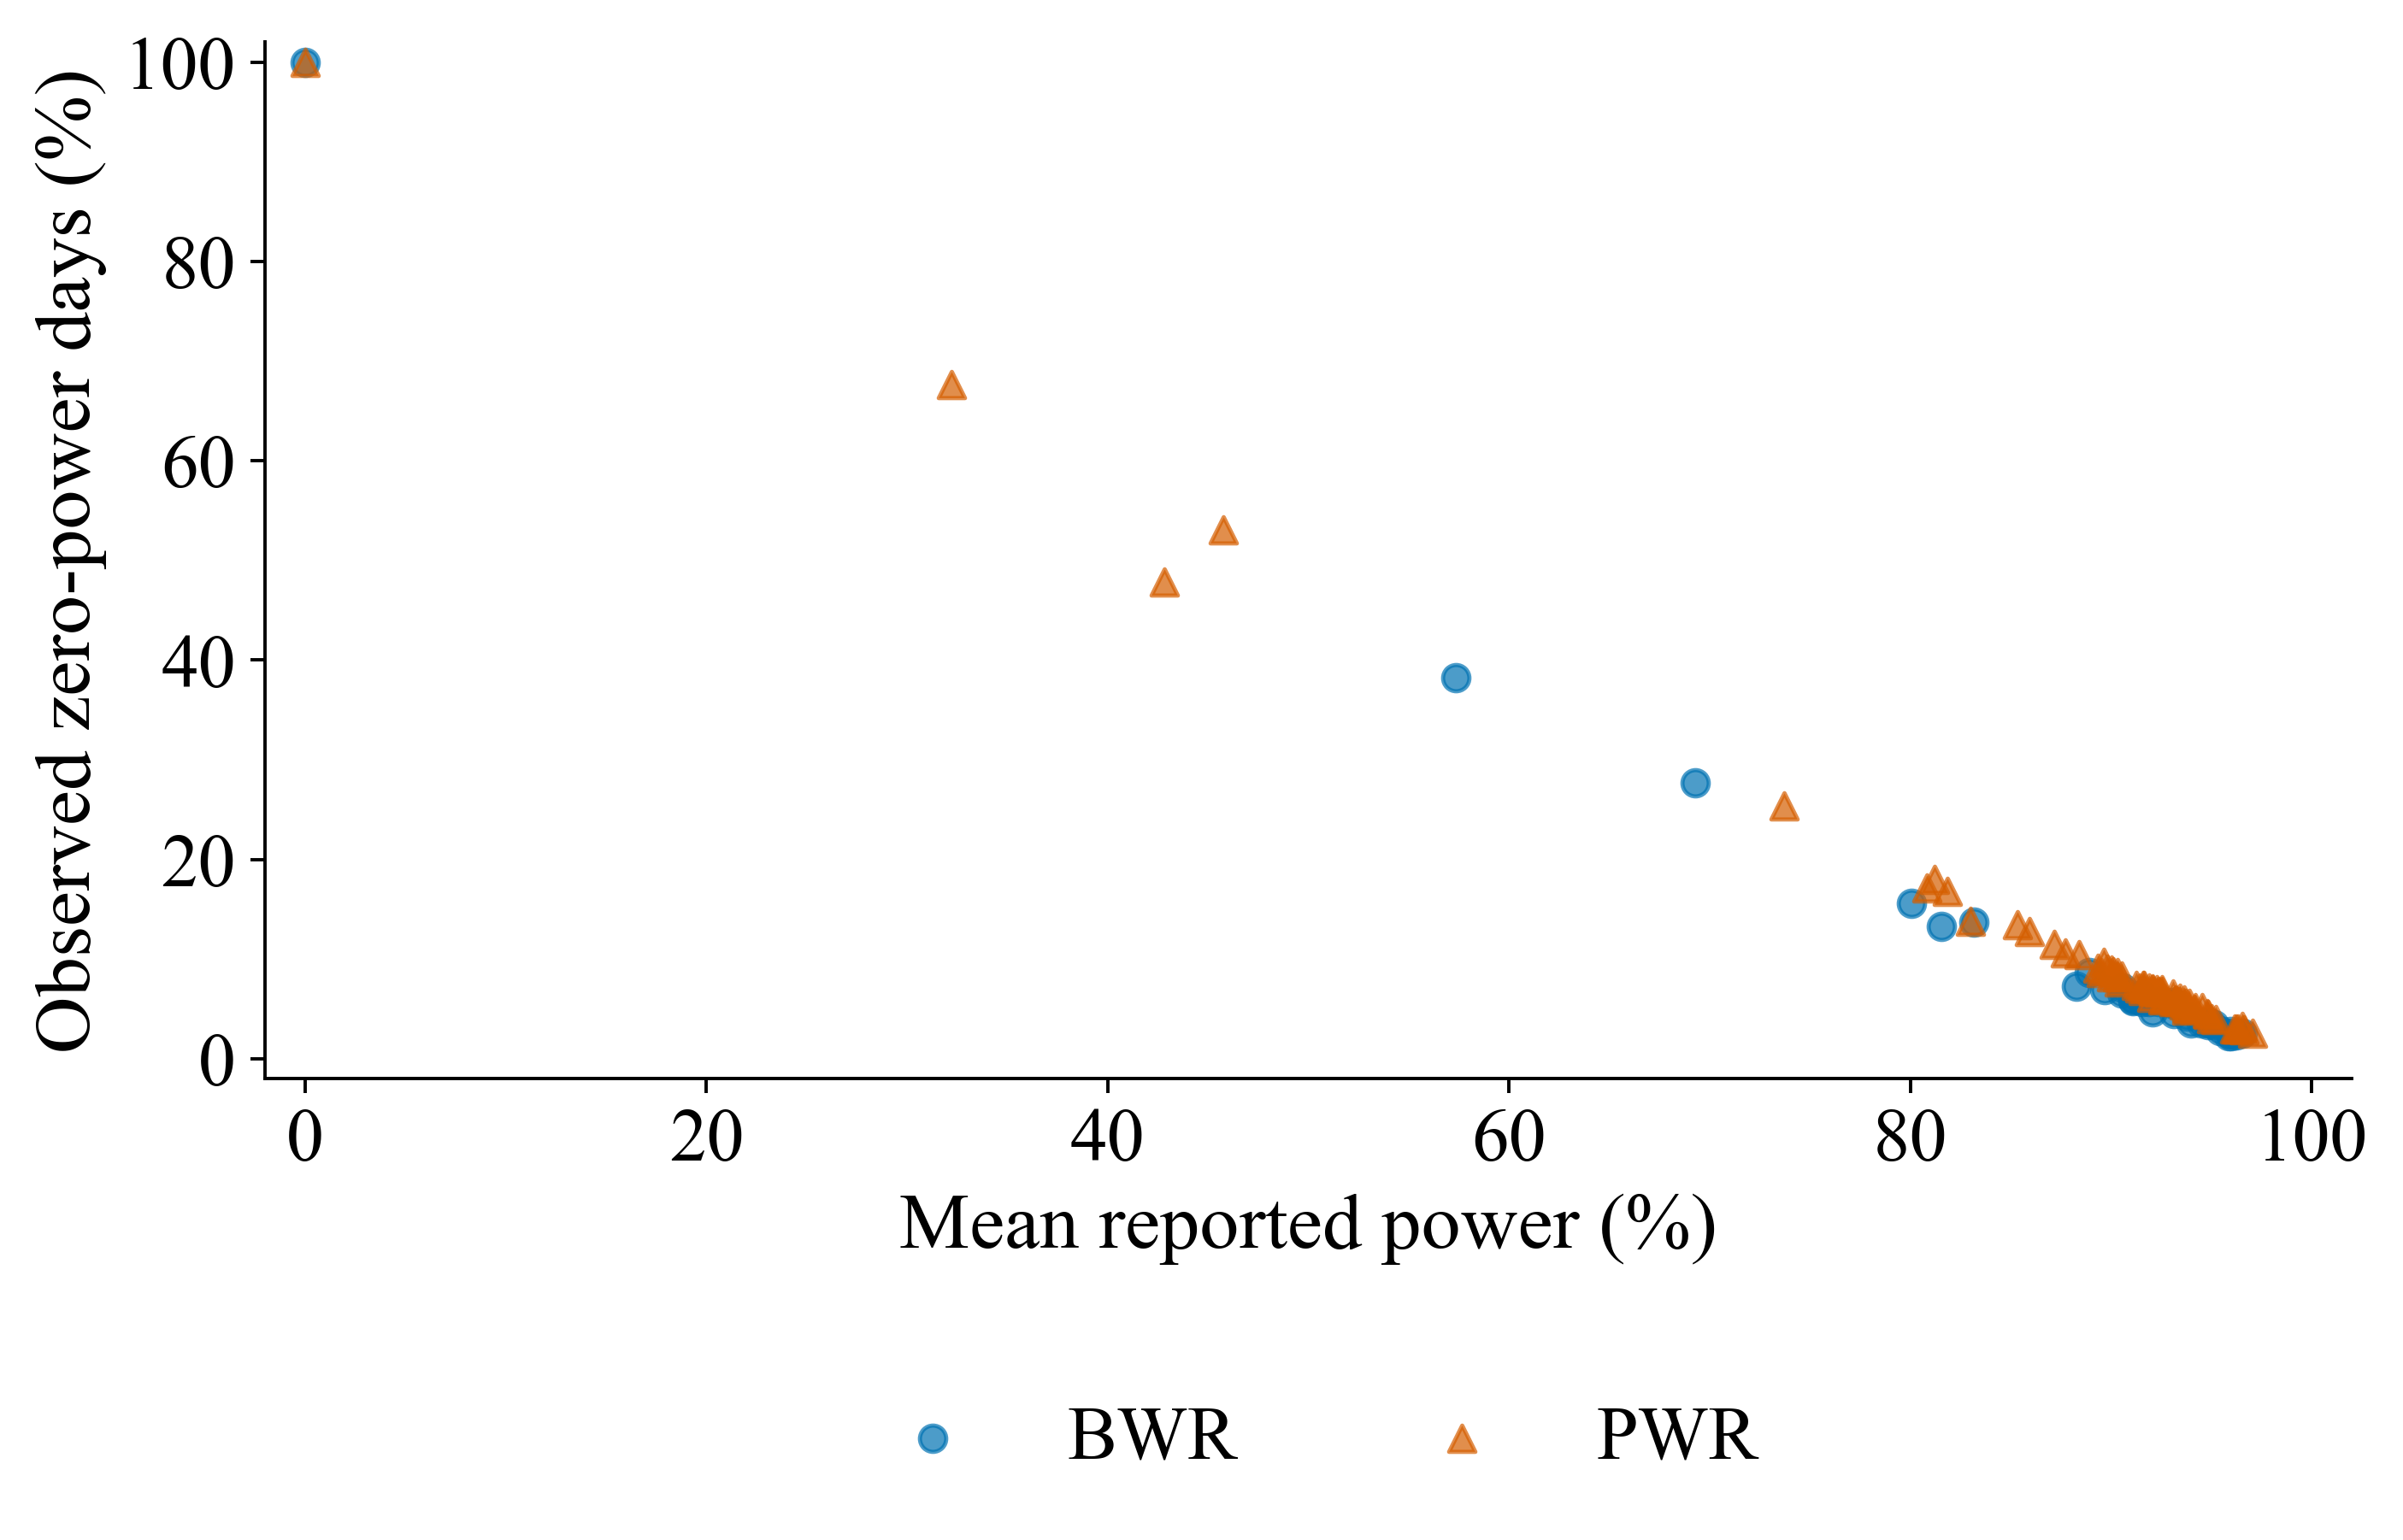

Mean power and fraction of zero days by reactor. Historically retired units remain in source-level descriptive analysis; days beyond known shutdown dates are excluded from the operational modeling cohort.

In [27]:
reactor_summary = dev_power.groupby(["reactor_id", "plant_id", "reactor_type"]).agg(mean_power=("power_pct", "mean"), sd_power=("power_pct", "std"), zero_fraction=("power_pct", lambda s:s.eq(0).mean()), n=("power_pct", "size")).reset_index()
scientific_table(reactor_summary.groupby("reactor_type").agg(reactors=("reactor_id", "size"), median_mean_power=("mean_power", "median"), q25_mean_power=("mean_power", lambda s:s.quantile(.25)), q75_mean_power=("mean_power", lambda s:s.quantile(.75)), median_zero_fraction=("zero_fraction", "median")).reset_index(), "nb01_reactor_heterogeneity", "Between-reactor heterogeneity; reactors receive equal weight in the quartiles")
fig, ax = plt.subplots(figsize=(9, 4.5))
for reactor_type, color, marker in [("BWR", "#0072B2", "o"), ("PWR", "#D55E00", "^")]:
    group = reactor_summary.loc[reactor_summary.reactor_type.eq(reactor_type)]
    ax.scatter(group.mean_power, 100*group.zero_fraction, color=color, marker=marker, s=40, alpha=.7, label=reactor_type)
ax.set(xlabel="Mean reported power (%)", ylabel="Observed zero-power days (%)", xlim=(-2, 102), ylim=(-2, 102))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.25), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_reactor_heterogeneity", reactor_summary, "Mean power and fraction of zero days by reactor. Historically retired units remain in source-level descriptive analysis; days beyond known shutdown dates are excluded from the operational modeling cohort.")

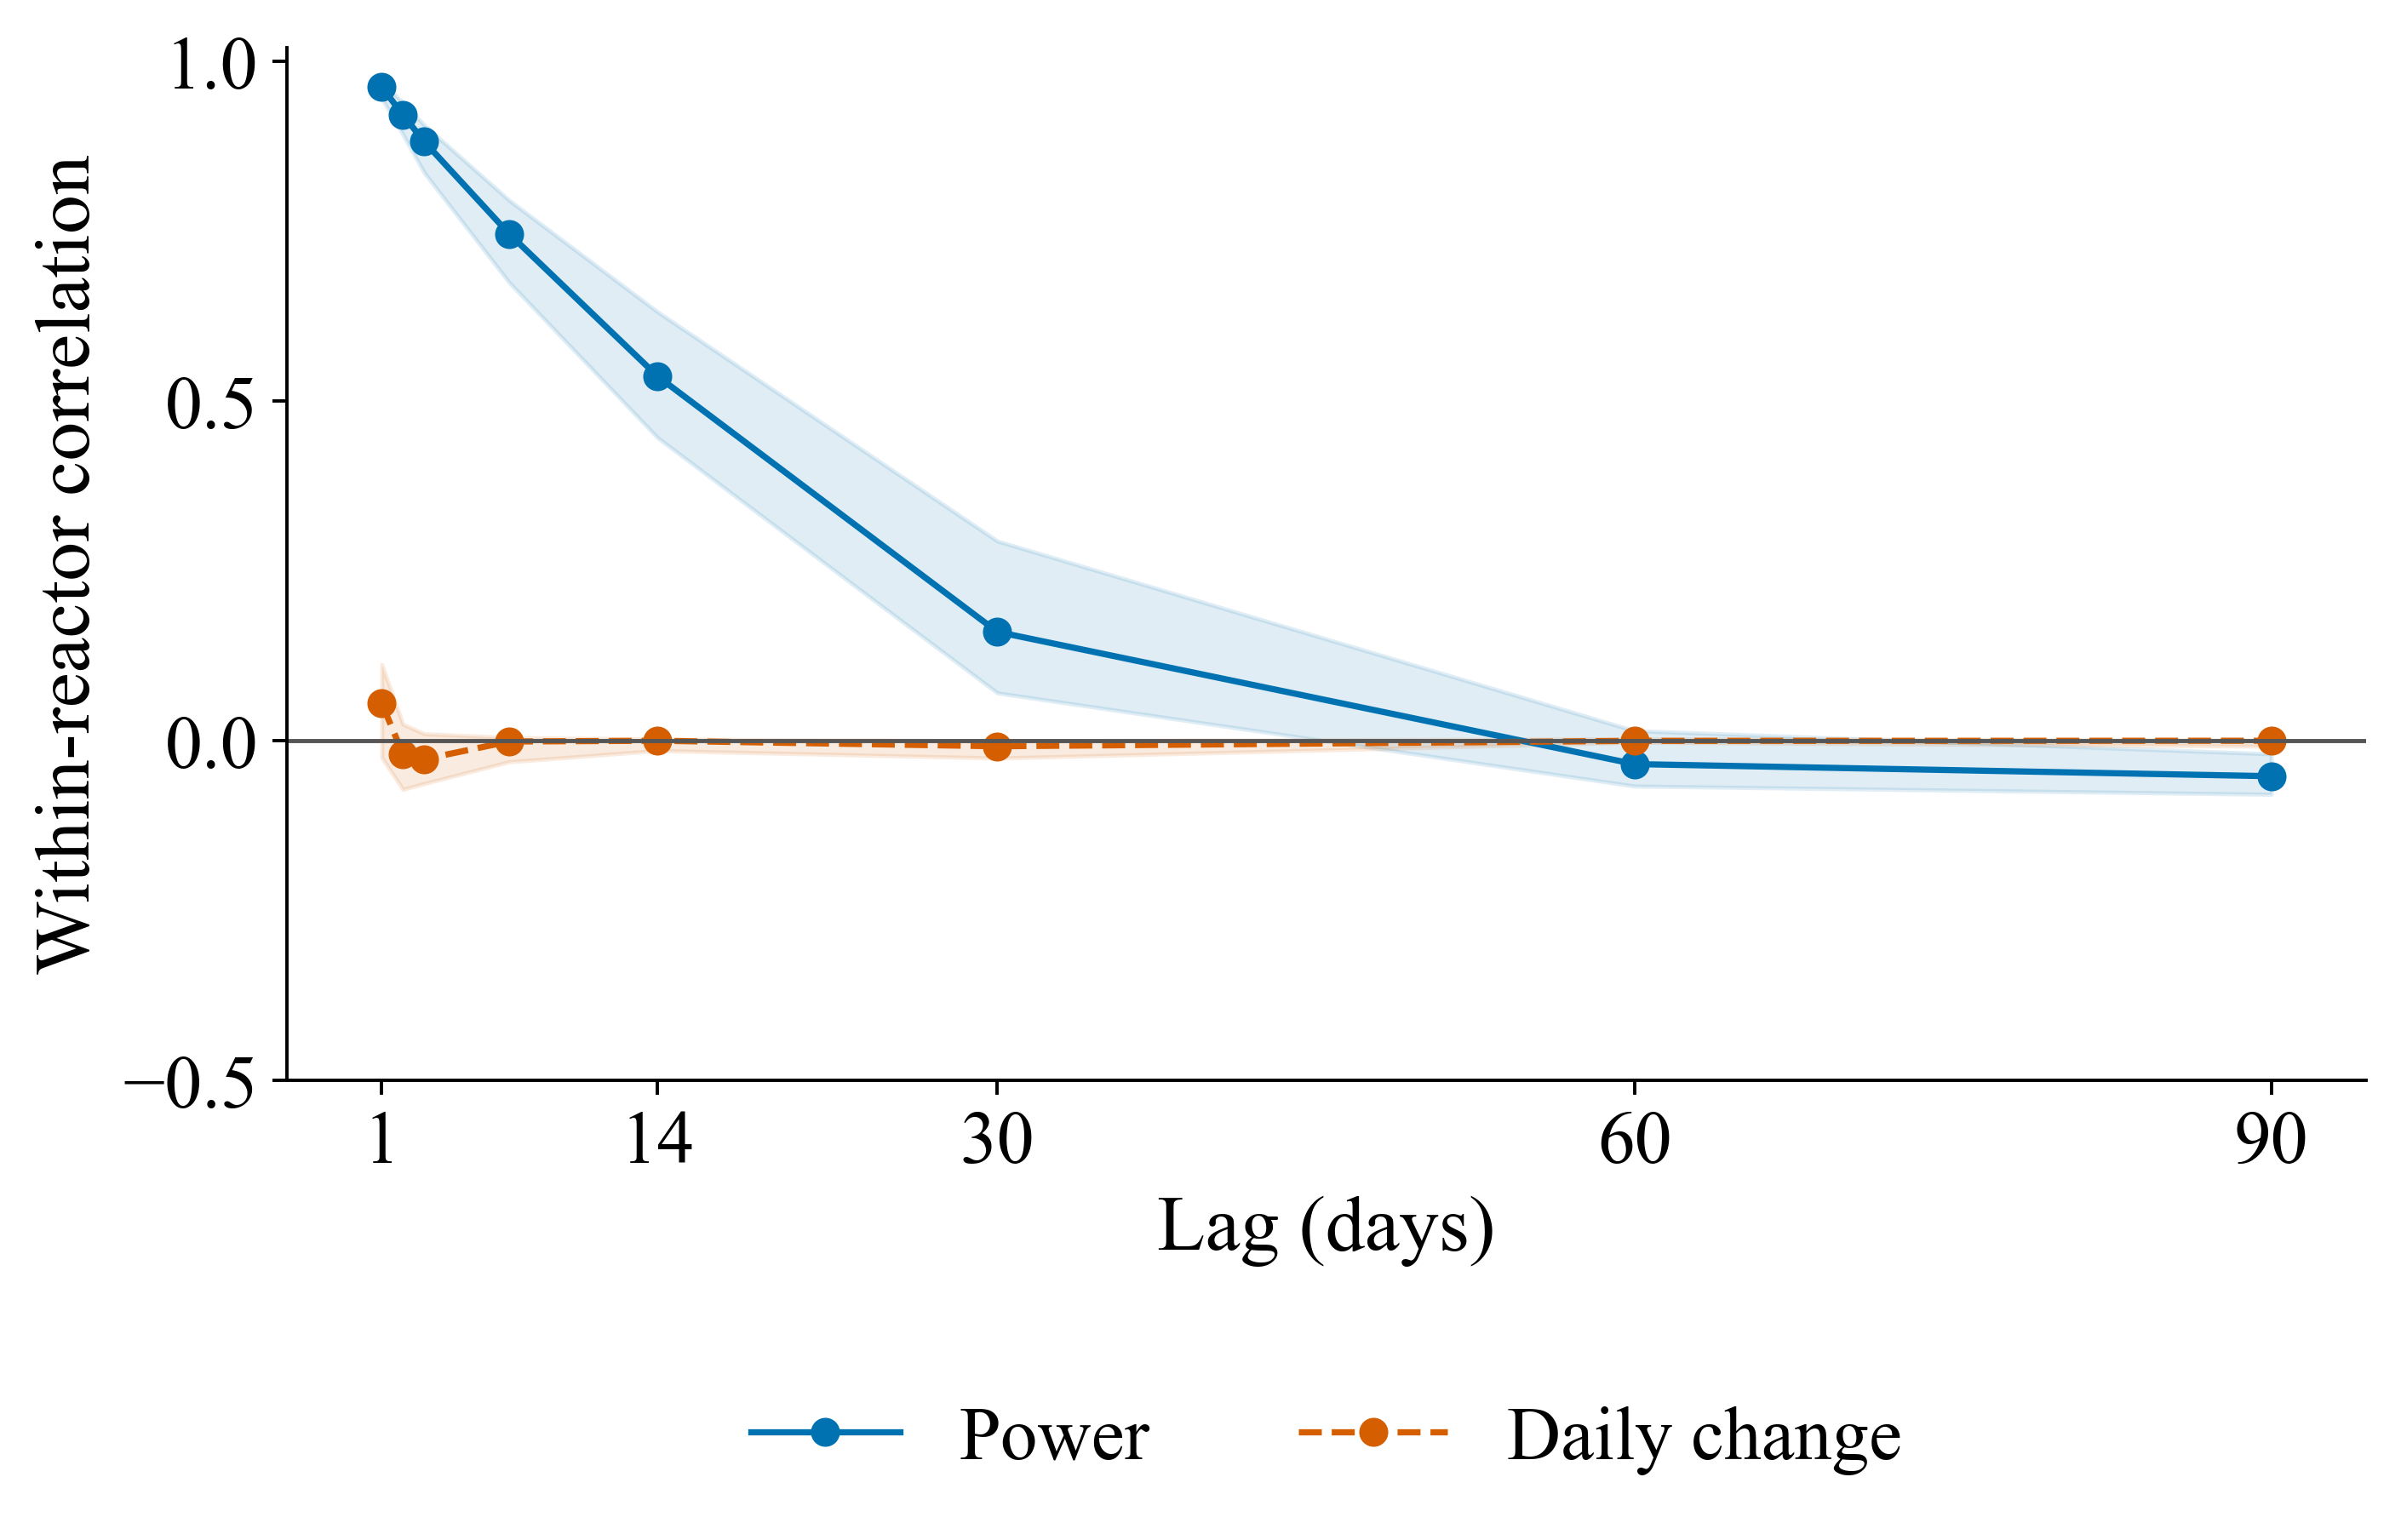

Median autocorrelation and interquartile range across reactors. Constant series are excluded only from correlation analysis. The band describes reactor heterogeneity, not a confidence interval. Overlapping windows are not independent experiments.

In [28]:
acf_records = []
for reactor_id, group in dev_power.groupby("reactor_id", sort=False):
    series = group.set_index("date").power_pct.asfreq("D")
    for representation, values in [("Power", series), ("Daily change", series.diff())]:
        for lag in [1, 2, 3, 7, 14, 30, 60, 90]:
            paired = pd.concat([values, values.shift(lag)], axis=1).dropna()
            if len(paired) >= 100 and paired.nunique().gt(1).all():
                acf_records.append({"reactor_id":reactor_id, "Representation":representation, "Lag":lag, "r":paired.iloc[:,0].corr(paired.iloc[:,1])})
acf_frame = pd.DataFrame(acf_records)
acf_summary = acf_frame.groupby(["Representation", "Lag"]).agg(median=("r", "median"), q25=("r", lambda s:s.quantile(.25)), q75=("r", lambda s:s.quantile(.75)), reactors=("reactor_id", "nunique")).reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
for representation, color, style in [("Power", "#0072B2", "-"), ("Daily change", "#D55E00", "--")]:
    group = acf_summary.loc[acf_summary.Representation.eq(representation)]
    ax.plot(group.Lag, group["median"], color=color, ls=style, marker="o", label=representation)
    ax.fill_between(group.Lag, group.q25, group.q75, color=color, alpha=.12)
ax.axhline(0, color="#555555", lw=1)
ax.set(xlabel="Lag (days)", ylabel="Within-reactor correlation", ylim=(-.5, 1.02), xticks=[1, 14, 30, 60, 90])
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.25), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
publication_figure(fig, "nb01_temporal_dependence", acf_summary, "Median autocorrelation and interquartile range across reactors. Constant series are excluded only from correlation analysis. The band describes reactor heterogeneity, not a confidence interval. Overlapping windows are not independent experiments.")

## Information boundaries and decisions before training

In [29]:
information_boundary = pd.DataFrame([
    ("Power history", "Through report date t", "Report publication time not archived; retrospective daily study"),
    ("NOAA weather", "Weather date at most t−3 days", "Archive revisions and longer publication delays remain possible"),
    ("EIA changing attributes", "Source year at most year(t)−2", "Missing early history is retained as missing"),
    ("Reactor type / identity", "Historical physical identifier", "Current age, future capacity factors and current status excluded"),
    ("SCRAM codes, report power, event IDs", "Labels and audit only", "Never model predictors"),
    ("Calibration labels", "After architecture selection", "No architecture changes based on calibration scores"),
    ("Locked-test labels", "NB06 after model freeze", "No tuning after test access")], columns=["Information", "Permitted boundary", "Limitation / safeguard"])
scientific_table(information_boundary, "nb01_information_boundary", "Source availability and leakage prevention")
protocol = {"run_id": RUN_ID, "target":"previous-day independently documented SCRAM", "prediction_semantics":"retrospective daily recognition; not pre-event forecasting", "primary_metric":"average_precision", "seeds":[42,137,2026],
    "train_years":[2019,2020,2021,2022], "development_year":2023, "calibration_year":2024, "locked_test_year":2025,
    "window_candidates_days":[7,14,30], "embargo_days":30, "weather_lag_days":3, "eia_lag_years":2,
    "stable_control_days":7, "stable_control_max_range_pp":2, "event_control_exclusion_days":7,
    "primary_threshold_rule":"F1 maximum on calibration, ties choose higher threshold", "false_alarm_limit_per_1000_control_days":1,
    "calibration_method":"logistic sigmoid on 2024 calibration split", "bootstrap_unit":"physical site cluster retaining all selected dates and episodes", "bootstrap_replicates":2000,
    "claim_boundary":"selected observable cohort; no nuclear control, no international validation claim", "test_opened_for_model_selection":False, "archive_label_rule":"A/R or M/R and (RX Crit Y or critical RPS category); curated date overrides by reactor and event ID", "label_ambiguity_exclusion":"all mapped A/R and M/R notifications exclude nearby controls even without full confirmation", "permanent_shutdown_exclusion":"exclude after shutdown date plus one report day where source date exists", "secondary_metrics":["ROC-AUC","MCC","Balanced Accuracy","Precision","Recall","F1","Brier","event recall","false alarms per 1000 eligible controls"], "model_selection_rule":"development AP with chronological internal folds and site-transfer diagnostics; test never consulted", "initial_search_policy":"small explicit configuration grids per family, three seed repeats; any development expansion logged before calibration", "multiclass_status":"exploratory only; 12 manual SCRAM days in development 2023 insufficient for primary three-class claim", "label_sensitivity":["curated_only","archive_agreement_only","date_alignment_plus_minus_one_day"], "natural_weather_stress":"NOAA GSOD update cessation after 2025-08-29; retain missing values"}
(OUTPUT_ROOT / "Configs/experiment.yaml").write_text(__import__("yaml").safe_dump(protocol, allow_unicode=True, sort_keys=False))
for split in ["train", "development", "calibration", "locked_test"]:
    rows = observations.loc[observations.split.eq(split)].copy()
    rows.to_parquet(SHARED_DATASET_ROOT / f"Interim/{split}_observations.parquet", index=False)
power.to_parquet(SHARED_DATASET_ROOT / "Processed/nrc_power_weather.parquet", index=False)


**Source availability and leakage prevention**

Information,Permitted boundary,Limitation / safeguard
Power history,Through report date t,Report publication time not archived; retrospective daily study
NOAA weather,Weather date at most t−3 days,Archive revisions and longer publication delays remain possible
EIA changing attributes,Source year at most year(t)−2,Missing early history is retained as missing
Reactor type / identity,Historical physical identifier,"Current age, future capacity factors and current status excluded"
"SCRAM codes, report power, event IDs",Labels and audit only,Never model predictors
Calibration labels,After architecture selection,No architecture changes based on calibration scores
Locked-test labels,NB06 after model freeze,No tuning after test access
